
# Student Stress Analysis and Classification Using Machine Learning

## Part 1: Exploratory Data Analysis and Data Preprocessing

This project aims to analyze academic and lifestyle factors affecting college students' perceived stress levels and develop a machine learning classification model.

The dataset consists of student responses collected through a Google Form.

This notebook focuses on:
1. Exploratory Data Analysis (EDA)
2. Data Cleaning
3. Data Preprocessing


In [ ]:

# Importing the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignore unnecessary warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')


Mounted at /content/drive



##  Loading the Dataset

We will load the student stress questionnaire responses from Google Drive using Pandas.

The dataset was collected through Google Forms and exported in CSV format.


In [ ]:

# Specify the CSV file path

file_path = '/content/drive/MyDrive/Student/Student_Academic_Stress_300_rows.csv'

# Load the dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!



## 3. Understanding the Dataset

Before performing EDA, we need to understand the size and structure of our dataset.

We will check the total number of rows and columns.


In [ ]:

# Check the number of rows and columns

print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (300, 12)
Total Rows: 300
Total Columns: 12



## 4. Understanding Dataset Columns

We will examine all column names to identify the questionnaire features and the target variable.

This helps us understand which variables will be used for machine learning.


In [ ]:

# Display all column names

for column in df.columns:
    print(column)


Timestamp
How often have unexpected academic difficulties or changes in your study plans disrupted your routine?
How often have you found the amount of academic work you needed to complete difficult to manage?
How often have you struggled to complete assignments, projects, or other academic tasks within their deadlines?
How often have examinations or academic assessments caused you concern about your academic performance?
How often have concerns about placements, internships, employment, or your future career affected your academic life?
How often have you had difficulty getting enough good-quality sleep because of your academic routine or related concerns?
How often have you struggled to allocate enough time to your different academic responsibilities?
How often have you felt that important academic responsibilities were beyond your control?
How often have you felt that you lacked support from friends, family, classmates, or others when facing academic difficulties?
How often have res


## 5. Dataset Information and Data Types

We will examine the data types of each column and check the overall structure of the dataset.

This helps identify whether the variables are numerical or categorical and whether any conversion is required.


In [ ]:

# Display dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 12 columns):
 #   Column                                                                                                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                --------------  ----- 
 0   Timestamp                                                                                                                                                                                             300 non-null    object
 1   How often have unexpected academic difficulties or changes in your study plans disrupted your routine?                                                                                                300 non-null  


## 6. Statistical Summary of the Dataset

We will generate descriptive statistics to understand the distribution and characteristics of the numerical columns.

Since the questionnaire responses are currently categorical, we will first examine the frequency distribution of the responses.


In [ ]:

# Statistical summary of categorical columns

df.describe(include='all').T


,count,unique,top,freq
Timestamp,300,300,10/10/2026 17:39:02,1
How often have unexpected academic difficulties or changes in your study plans disrupted your routine?,300,5,Sometimes,98
How often have you found the amount of academic work you needed to complete difficult to manage?,300,5,Fairly Often,121
"How often have you struggled to complete assignments, projects, or other academic tasks within their deadlines?",299,5,Sometimes,143
How often have examinations or academic assessments caused you concern about your academic performance?,300,5,Very Often,109
"How often have concerns about placements, internships, employment, or your future career affected your academic life?",300,5,Very Often,113
How often have you had difficulty getting enough good-quality sleep because of your academic routine or related concerns?,300,5,Very Often,88
How often have you struggled to allocate enough time to your different academic responsibilities?,299,5,Fairly Often,95
How often have you felt that important academic responsibilities were beyond your control?,299,5,Sometimes,101
"How often have you felt that you lacked support from friends, family, classmates, or others when facing academic difficulties?",300,5,Sometimes,95



## 7. Missing Value Analysis

Missing values occur when respondents leave certain questionnaire questions unanswered.

Identifying missing values is important because they can affect data analysis and machine learning model performance.

We will calculate the number and percentage of missing values in every column.


In [ ]:

# Count missing values in each column

missing_values = df.isnull().sum()

# Calculate missing value percentage
missing_percentage = (missing_values / len(df)) * 100

# Combine the results
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_summary)


,Missing Values,Missing Percentage
Timestamp,0,0.000000
How often have unexpected academic difficulties or changes in your study plans disrupted your routine?,0,0.000000
How often have you found the amount of academic work you needed to complete difficult to manage?,0,0.000000
"How often have you struggled to complete assignments, projects, or other academic tasks within their deadlines?",1,0.333333
How often have examinations or academic assessments caused you concern about your academic performance?,0,0.000000
"How often have concerns about placements, internships, employment, or your future career affected your academic life?",0,0.000000
How often have you had difficulty getting enough good-quality sleep because of your academic routine or related concerns?,0,0.000000
How often have you struggled to allocate enough time to your different academic responsibilities?,1,0.333333
How often have you felt that important academic responsibilities were beyond your control?,1,0.333333
"How often have you felt that you lacked support from friends, family, classmates, or others when facing academic difficulties?",0,0.000000


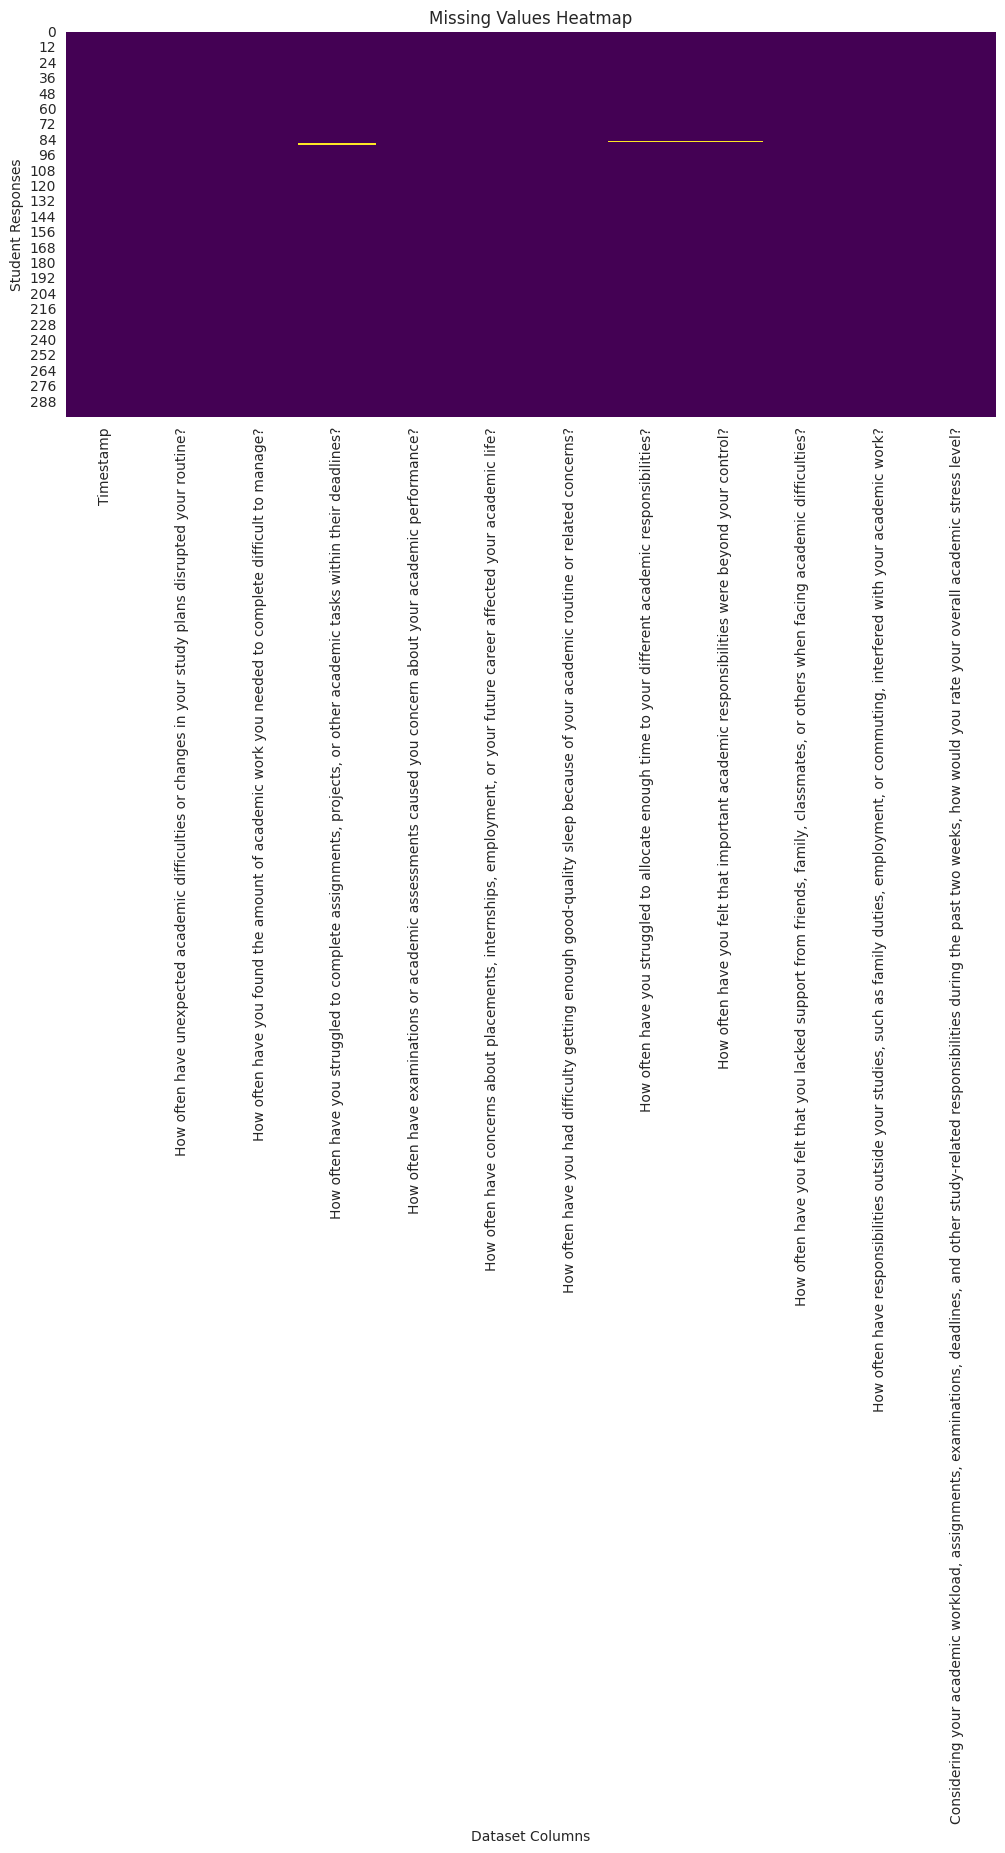

In [ ]:

# Visualize missing values

plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values Heatmap")
plt.xlabel("Dataset Columns")
plt.ylabel("Student Responses")

plt.xticks(rotation=90)
plt.show()



## 8. Duplicate Record Analysis

Duplicate records are identical rows that may have been accidentally included more than once.

We will identify duplicate records to ensure that repeated entries do not distort our analysis.


In [ ]:

# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)


Total Duplicate Rows: 0



## 9. Target Variable Distribution

The target variable represents the overall academic stress level reported by each student.

It contains three categories:
- Low
- Medium
- High

We will examine the frequency and percentage of each category to understand the distribution of stress levels in our dataset.

This analysis is important for identifying class imbalance before classification.


In [ ]:

# Identify the target column

target_column = df.columns[-1]

# Count each stress category
stress_counts = df[target_column].value_counts()

# Calculate percentages
stress_percentage = df[target_column].value_counts(normalize=True) * 100

# Create summary table
stress_summary = pd.DataFrame({
    'Number of Students': stress_counts,
    'Percentage': stress_percentage.round(2)
})

display(stress_summary)


,Number of Students,Percentage
"Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?",,
Medium,127,42.33
High,127,42.33
Low,46,15.33


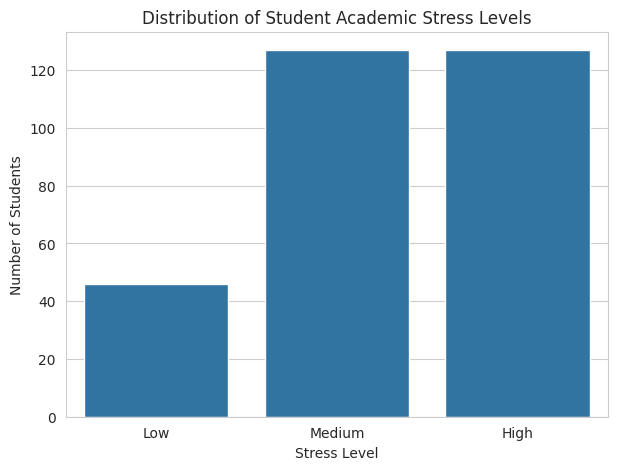

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target_column,
    order=['Low', 'Medium', 'High']
)

plt.title("Distribution of Student Academic Stress Levels")
plt.xlabel("Stress Level")
plt.ylabel("Number of Students")

plt.show()



## 10. Univariate Analysis of Questionnaire Features

Univariate analysis examines one variable at a time.

In this project, we will analyze the frequency of responses for each of the ten academic and lifestyle factors.

The questionnaire uses five response categories:
- Never
- Almost Never
- Sometimes
- Fairly Often
- Very Often

This analysis will help us understand how frequently students experience different academic and lifestyle difficulties.


In [ ]:

# Select the ten questionnaire feature columns

feature_columns = list(df.columns[1:11])

print("Total Input Features:", len(feature_columns))

for column in feature_columns:
    print(column)


Total Input Features: 10
How often have unexpected academic difficulties or changes in your study plans disrupted your routine?
How often have you found the amount of academic work you needed to complete difficult to manage?
How often have you struggled to complete assignments, projects, or other academic tasks within their deadlines?
How often have examinations or academic assessments caused you concern about your academic performance?
How often have concerns about placements, internships, employment, or your future career affected your academic life?
How often have you had difficulty getting enough good-quality sleep because of your academic routine or related concerns?
How often have you struggled to allocate enough time to your different academic responsibilities?
How often have you felt that important academic responsibilities were beyond your control?
How often have you felt that you lacked support from friends, family, classmates, or others when facing academic difficulties?
How

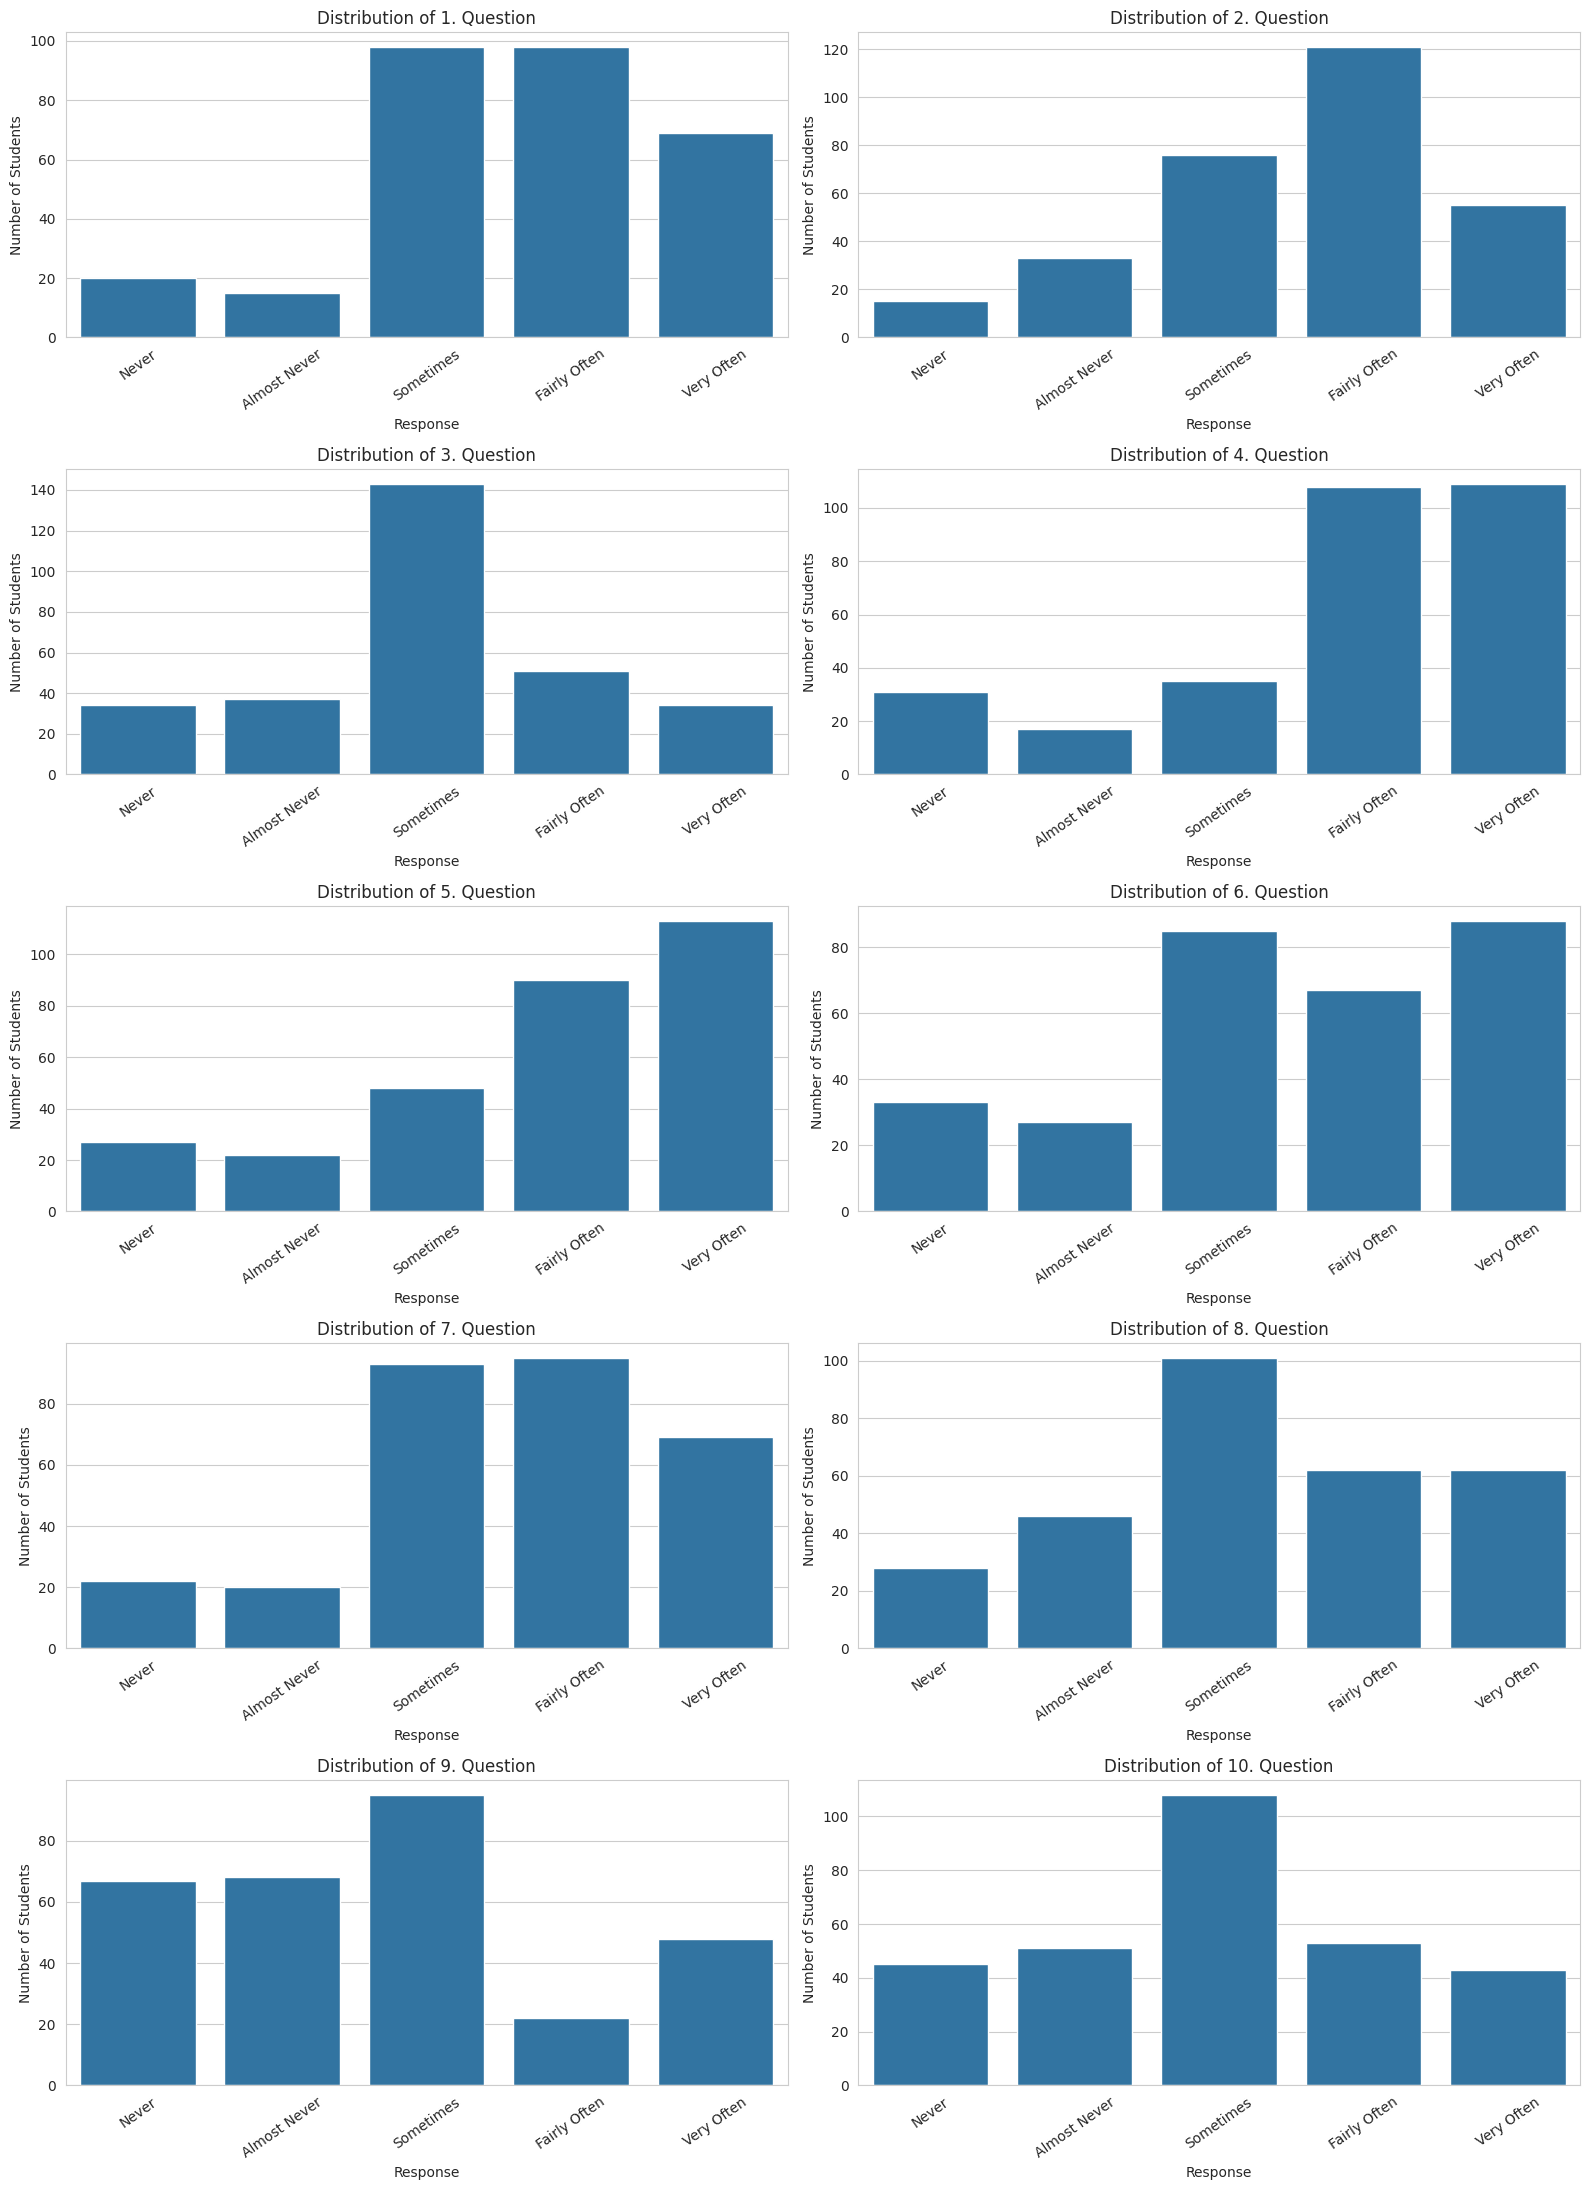

In [ ]:

# Define the order of Likert responses

response_order = [
    'Never',
    'Almost Never',
    'Sometimes',
    'Fairly Often',
    'Very Often'
]

# Create subplots for all ten features
fig, axes = plt.subplots(5, 2, figsize=(16, 22))

axes = axes.flatten()

for i, column in enumerate(feature_columns):

    sns.countplot(
        data=df,
        x=column,
        order=response_order,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {i+1}. Question")
    axes[i].set_xlabel("Response")
    axes[i].set_ylabel("Number of Students")

    axes[i].tick_params(axis='x', rotation=35)

plt.tight_layout()
plt.show()



## 12. Encoding Likert Scale Responses

The questionnaire responses are categorical text values.

However, the machine learning algorithms used in this project require numerical input.

Therefore, we will convert the five Likert response categories into numerical values while preserving their natural order.

Mapping:

- Never = 1
- Almost Never = 2
- Sometimes = 3
- Fairly Often = 4
- Very Often = 5

A higher score represents a higher frequency of experiencing the corresponding difficulty or concern.


In [ ]:

# Define Likert scale mapping

likert_mapping = {
    'Never': 1,
    'Almost Never': 2,
    'Sometimes': 3,
    'Fairly Often': 4,
    'Very Often': 5
}

# Create a copy of the original dataset
df_encoded = df.copy()

# Convert the ten questionnaire features
for column in feature_columns:
    df_encoded[column] = (
        df_encoded[column]
        .astype('string')
        .str.strip()
        .map(likert_mapping)
    )

# Display the converted dataset
df_encoded.head()


,Timestamp,How often have unexpected academic difficulties or changes in your study plans disrupted your routine?,How often have you found the amount of academic work you needed to complete difficult to manage?,"How often have you struggled to complete assignments, projects, or other academic tasks within their deadlines?",How often have examinations or academic assessments caused you concern about your academic performance?,"How often have concerns about placements, internships, employment, or your future career affected your academic life?",How often have you had difficulty getting enough good-quality sleep because of your academic routine or related concerns?,How often have you struggled to allocate enough time to your different academic responsibilities?,How often have you felt that important academic responsibilities were beyond your control?,"How often have you felt that you lacked support from friends, family, classmates, or others when facing academic difficulties?","How often have responsibilities outside your studies, such as family duties, employment, or commuting, interfered with your academic work?","Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?"
0,10/10/2026 17:39:02,3,4,2.0,4,5,3,4.0,2.0,1,2,Medium
1,10/10/2026 18:10:49,3,3,2.0,4,4,2,3.0,2.0,2,2,Medium
2,10/10/2026 20:17:09,5,3,4.0,5,4,3,4.0,3.0,2,3,High
3,10/10/2026 20:22:47,5,5,5.0,5,5,5,5.0,5.0,5,5,High
4,10/10/2026 20:36:39,3,4,3.0,4,4,3,3.0,2.0,2,2,High



## 13. Verification of Numerical Encoding

After encoding, we will verify that all questionnaire responses have been correctly converted into numerical values.

We will also check for unexpected response categories that may not have been included in our mapping.


In [ ]:

# Check data types
print("Data types after encoding:")
print(df_encoded[feature_columns].dtypes)

# Check unique values in each feature
for column in feature_columns:
    print(f"\n{column}")
    print(sorted(df_encoded[column].dropna().unique()))


Data types after encoding:
How often have unexpected academic difficulties or changes in your study plans disrupted your routine?                                          int64
How often have you found the amount of academic work you needed to complete difficult to manage?                                                int64
How often have you struggled to complete assignments, projects, or other academic tasks within their deadlines?                               float64
How often have examinations or academic assessments caused you concern about your academic performance?                                         int64
How often have concerns about placements, internships, employment, or your future career affected your academic life?                           int64
How often have you had difficulty getting enough good-quality sleep because of your academic routine or related concerns?                       int64
How often have you struggled to allocate enough time to your different ac


## 14. Feature Renaming and Dataset Organization

The original Google Forms column names are lengthy.

We will rename the ten questionnaire features using shorter and meaningful names.

This will make the dataset easier to understand, visualize and use during model development.

The Timestamp column will be excluded because it is not one of the ten proposed prediction features.


In [ ]:

# Define shorter feature names

new_feature_names = [
    'Unexpected_Difficulties',
    'Academic_Workload',
    'Deadline_Pressure',
    'Examination_Pressure',
    'Career_Pressure',
    'Sleep_Difficulties',
    'Time_Management',
    'Lack_of_Control',
    'Lack_of_Social_Support',
    'Competing_Responsibilities'
]

# Create a new dataset without Timestamp
clean_df = df_encoded.iloc[:, 1:11].copy()

# Rename the feature columns
clean_df.columns = new_feature_names

# Add target variable
clean_df['Stress_Level'] = (
    df[target_column]
    .astype('string')
    .str.strip()
    .str.title()
)

# Display the new dataset
clean_df.head()


,Unexpected_Difficulties,Academic_Workload,Deadline_Pressure,Examination_Pressure,Career_Pressure,Sleep_Difficulties,Time_Management,Lack_of_Control,Lack_of_Social_Support,Competing_Responsibilities,Stress_Level
0,3,4,2.0,4,5,3,4.0,2.0,1,2,Medium
1,3,3,2.0,4,4,2,3.0,2.0,2,2,Medium
2,5,3,4.0,5,4,3,4.0,3.0,2,3,High
3,5,5,5.0,5,5,5,5.0,5.0,5,5,High
4,3,4,3.0,4,4,3,3.0,2.0,2,2,High



## Bivariate Analysis: Relationship Between Features and Stress Level

Bivariate analysis is used to understand the relationship between two variables.

In our project, we will examine how academic and lifestyle factors vary across the three overall stress categories: Low, Medium and High.

This analysis will help us identify patterns in factors such as academic workload, examination pressure, sleep difficulties and deadline pressure across different stress groups.

We will use boxplots to compare the distributions of questionnaire responses across the stress categories.


In [ ]:
# Define the stress categories in order

stress_order = ['Low', 'Medium', 'High']

# Check target distribution

print(clean_df['Stress_Level'].value_counts())

Stress_Level
Medium    127
High      127
Low        46
Name: count, dtype: Int64



## 15. Handling Missing Values

Missing values can create problems during machine learning model training.

Our dataset contains three missing responses in the input features.

Since the target variable has no missing values, we will retain all student responses.

We will use median imputation to fill the missing input values.

The median is selected because it is less sensitive to extreme values than the mean and is suitable for ordered Likert-scale responses.

The imputation will be performed separately for each feature.


In [ ]:

# Check missing values before treatment

print("Missing values before imputation:")
print(clean_df.isnull().sum())


Missing values before imputation:
Unexpected_Difficulties       0
Academic_Workload             0
Deadline_Pressure             1
Examination_Pressure          0
Career_Pressure               0
Sleep_Difficulties            0
Time_Management               1
Lack_of_Control               1
Lack_of_Social_Support        0
Competing_Responsibilities    0
Stress_Level                  0
dtype: int64


In [ ]:

# Fill missing values using feature-wise median

for column in new_feature_names:

    median_value = clean_df[column].median()

    clean_df[column] = clean_df[column].fillna(median_value)

# Check missing values after imputation

print("Missing values after imputation:")
print(clean_df.isnull().sum())


Missing values after imputation:
Unexpected_Difficulties       0
Academic_Workload             0
Deadline_Pressure             0
Examination_Pressure          0
Career_Pressure               0
Sleep_Difficulties            0
Time_Management               0
Lack_of_Control               0
Lack_of_Social_Support        0
Competing_Responsibilities    0
Stress_Level                  0
dtype: int64



## 16. Descriptive Statistics of Numerical Features

After encoding and handling missing values, we will calculate descriptive statistics for the ten questionnaire features.

This will help us understand the central tendency and spread of student responses.

We will examine:
- Mean
- Median
- Standard deviation
- Minimum and maximum values
- Quartiles


In [ ]:

# Generate descriptive statistics

clean_df[new_feature_names].describe().T


,count,mean,std,min,25%,50%,75%,max
Unexpected_Difficulties,300.0,3.603333,1.096966,1.0,3.0,4.0,4.0,5.0
Academic_Workload,300.0,3.560000,1.066235,1.0,3.0,4.0,4.0,5.0
Deadline_Pressure,300.0,3.046667,1.096279,1.0,3.0,3.0,4.0,5.0
Examination_Pressure,300.0,3.823333,1.269183,1.0,3.0,4.0,5.0,5.0
Career_Pressure,300.0,3.800000,1.267025,1.0,3.0,4.0,5.0,5.0
Sleep_Difficulties,300.0,3.500000,1.297025,1.0,3.0,4.0,5.0,5.0
Time_Management,300.0,3.566667,1.132769,1.0,3.0,4.0,4.0,5.0
Lack_of_Control,300.0,3.280000,1.219244,1.0,3.0,3.0,4.0,5.0
Lack_of_Social_Support,300.0,2.720000,1.326952,1.0,2.0,3.0,3.0,5.0
Competing_Responsibilities,300.0,2.993333,1.234925,1.0,2.0,3.0,4.0,5.0



## 17. Distribution Analysis Using Boxplots

Boxplots help us understand the distribution of numerical questionnaire responses.

They display the median, quartiles, spread and potential outliers.

We will compare all ten questionnaire features to understand differences in their response distributions.


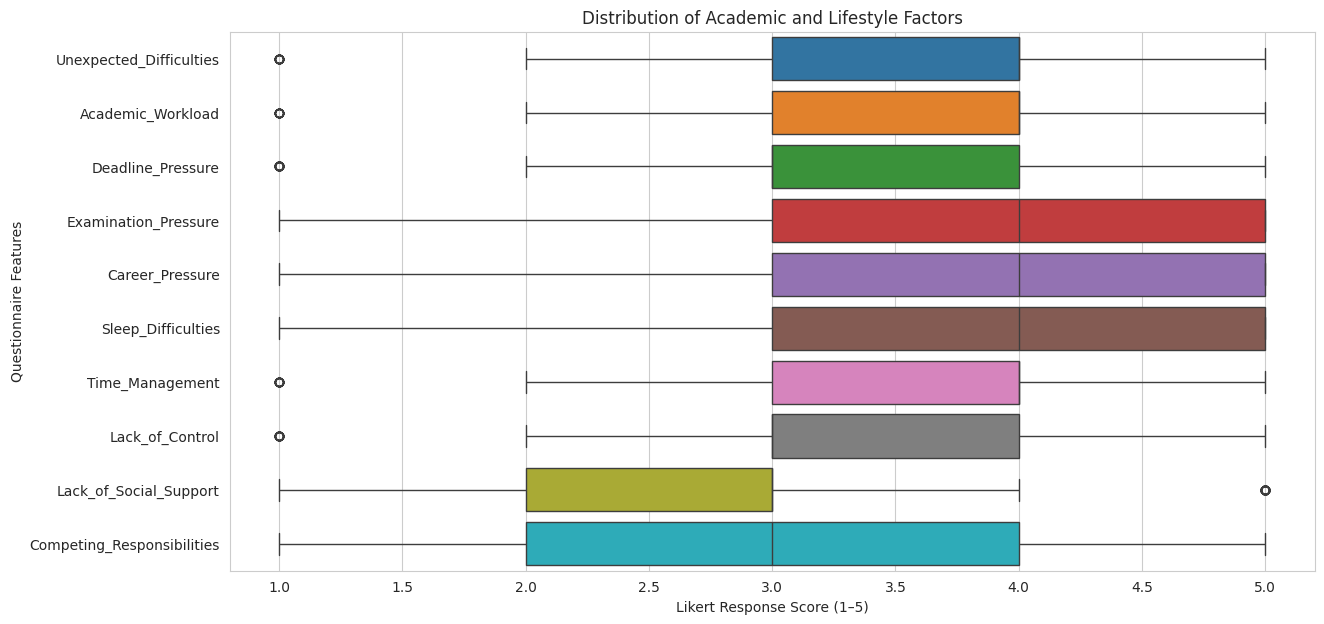

In [ ]:

plt.figure(figsize=(14, 7))

sns.boxplot(data=clean_df[new_feature_names], orient='h')

plt.title("Distribution of Academic and Lifestyle Factors")
plt.xlabel("Likert Response Score (1–5)")
plt.ylabel("Questionnaire Features")

plt.show()



## 18. Correlation Analysis Between Features

Correlation analysis helps identify relationships between different academic and lifestyle factors.

We will use Spearman correlation because our questionnaire responses are ordinal Likert-scale variables.

Spearman correlation measures the strength and direction of a monotonic relationship between two variables.

Correlation values range from -1 to +1:

- +1 indicates a perfect positive association.
- -1 indicates a perfect negative association.
- 0 indicates no monotonic association.


In [ ]:

# Calculate Spearman correlation

correlation_matrix = clean_df[new_feature_names].corr(
    method='spearman'
)

# Display correlation matrix
display(correlation_matrix)


,Unexpected_Difficulties,Academic_Workload,Deadline_Pressure,Examination_Pressure,Career_Pressure,Sleep_Difficulties,Time_Management,Lack_of_Control,Lack_of_Social_Support,Competing_Responsibilities
Unexpected_Difficulties,1.000000,0.514854,0.537464,0.457439,0.451016,0.360475,0.414655,0.537704,0.381174,0.511031
Academic_Workload,0.514854,1.000000,0.549207,0.540345,0.544536,0.448181,0.495931,0.515536,0.427757,0.469735
Deadline_Pressure,0.537464,0.549207,1.000000,0.548018,0.415833,0.518161,0.474240,0.513907,0.464921,0.505215
Examination_Pressure,0.457439,0.540345,0.548018,1.000000,0.579751,0.527094,0.563446,0.502537,0.399226,0.407112
Career_Pressure,0.451016,0.544536,0.415833,0.579751,1.000000,0.591807,0.534479,0.551451,0.416448,0.442815
Sleep_Difficulties,0.360475,0.448181,0.518161,0.527094,0.591807,1.000000,0.525738,0.517191,0.442858,0.445532
Time_Management,0.414655,0.495931,0.474240,0.563446,0.534479,0.525738,1.000000,0.452254,0.361464,0.397668
Lack_of_Control,0.537704,0.515536,0.513907,0.502537,0.551451,0.517191,0.452254,1.000000,0.609832,0.494775
Lack_of_Social_Support,0.381174,0.427757,0.464921,0.399226,0.416448,0.442858,0.361464,0.609832,1.000000,0.585036
Competing_Responsibilities,0.511031,0.469735,0.505215,0.407112,0.442815,0.445532,0.397668,0.494775,0.585036,1.000000


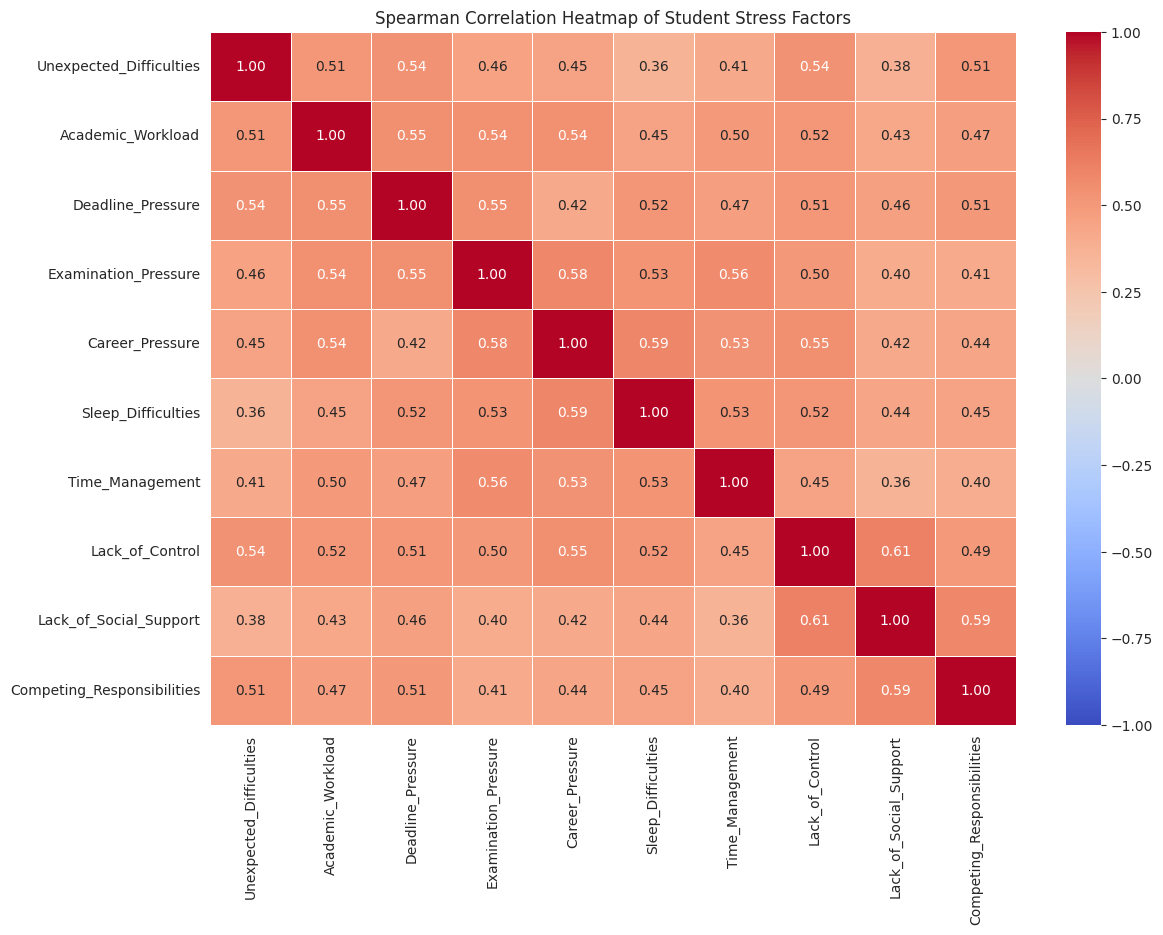

In [ ]:

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Heatmap of Student Stress Factors")

plt.show()



## 19. Comparing Features Across Stress Categories

We will examine how the ten questionnaire features vary across Low, Medium and High stress groups.

Boxplots will help us compare the distribution and median scores of each feature across the three target categories.

This analysis helps us identify which academic and lifestyle factors show different response patterns across stress groups.


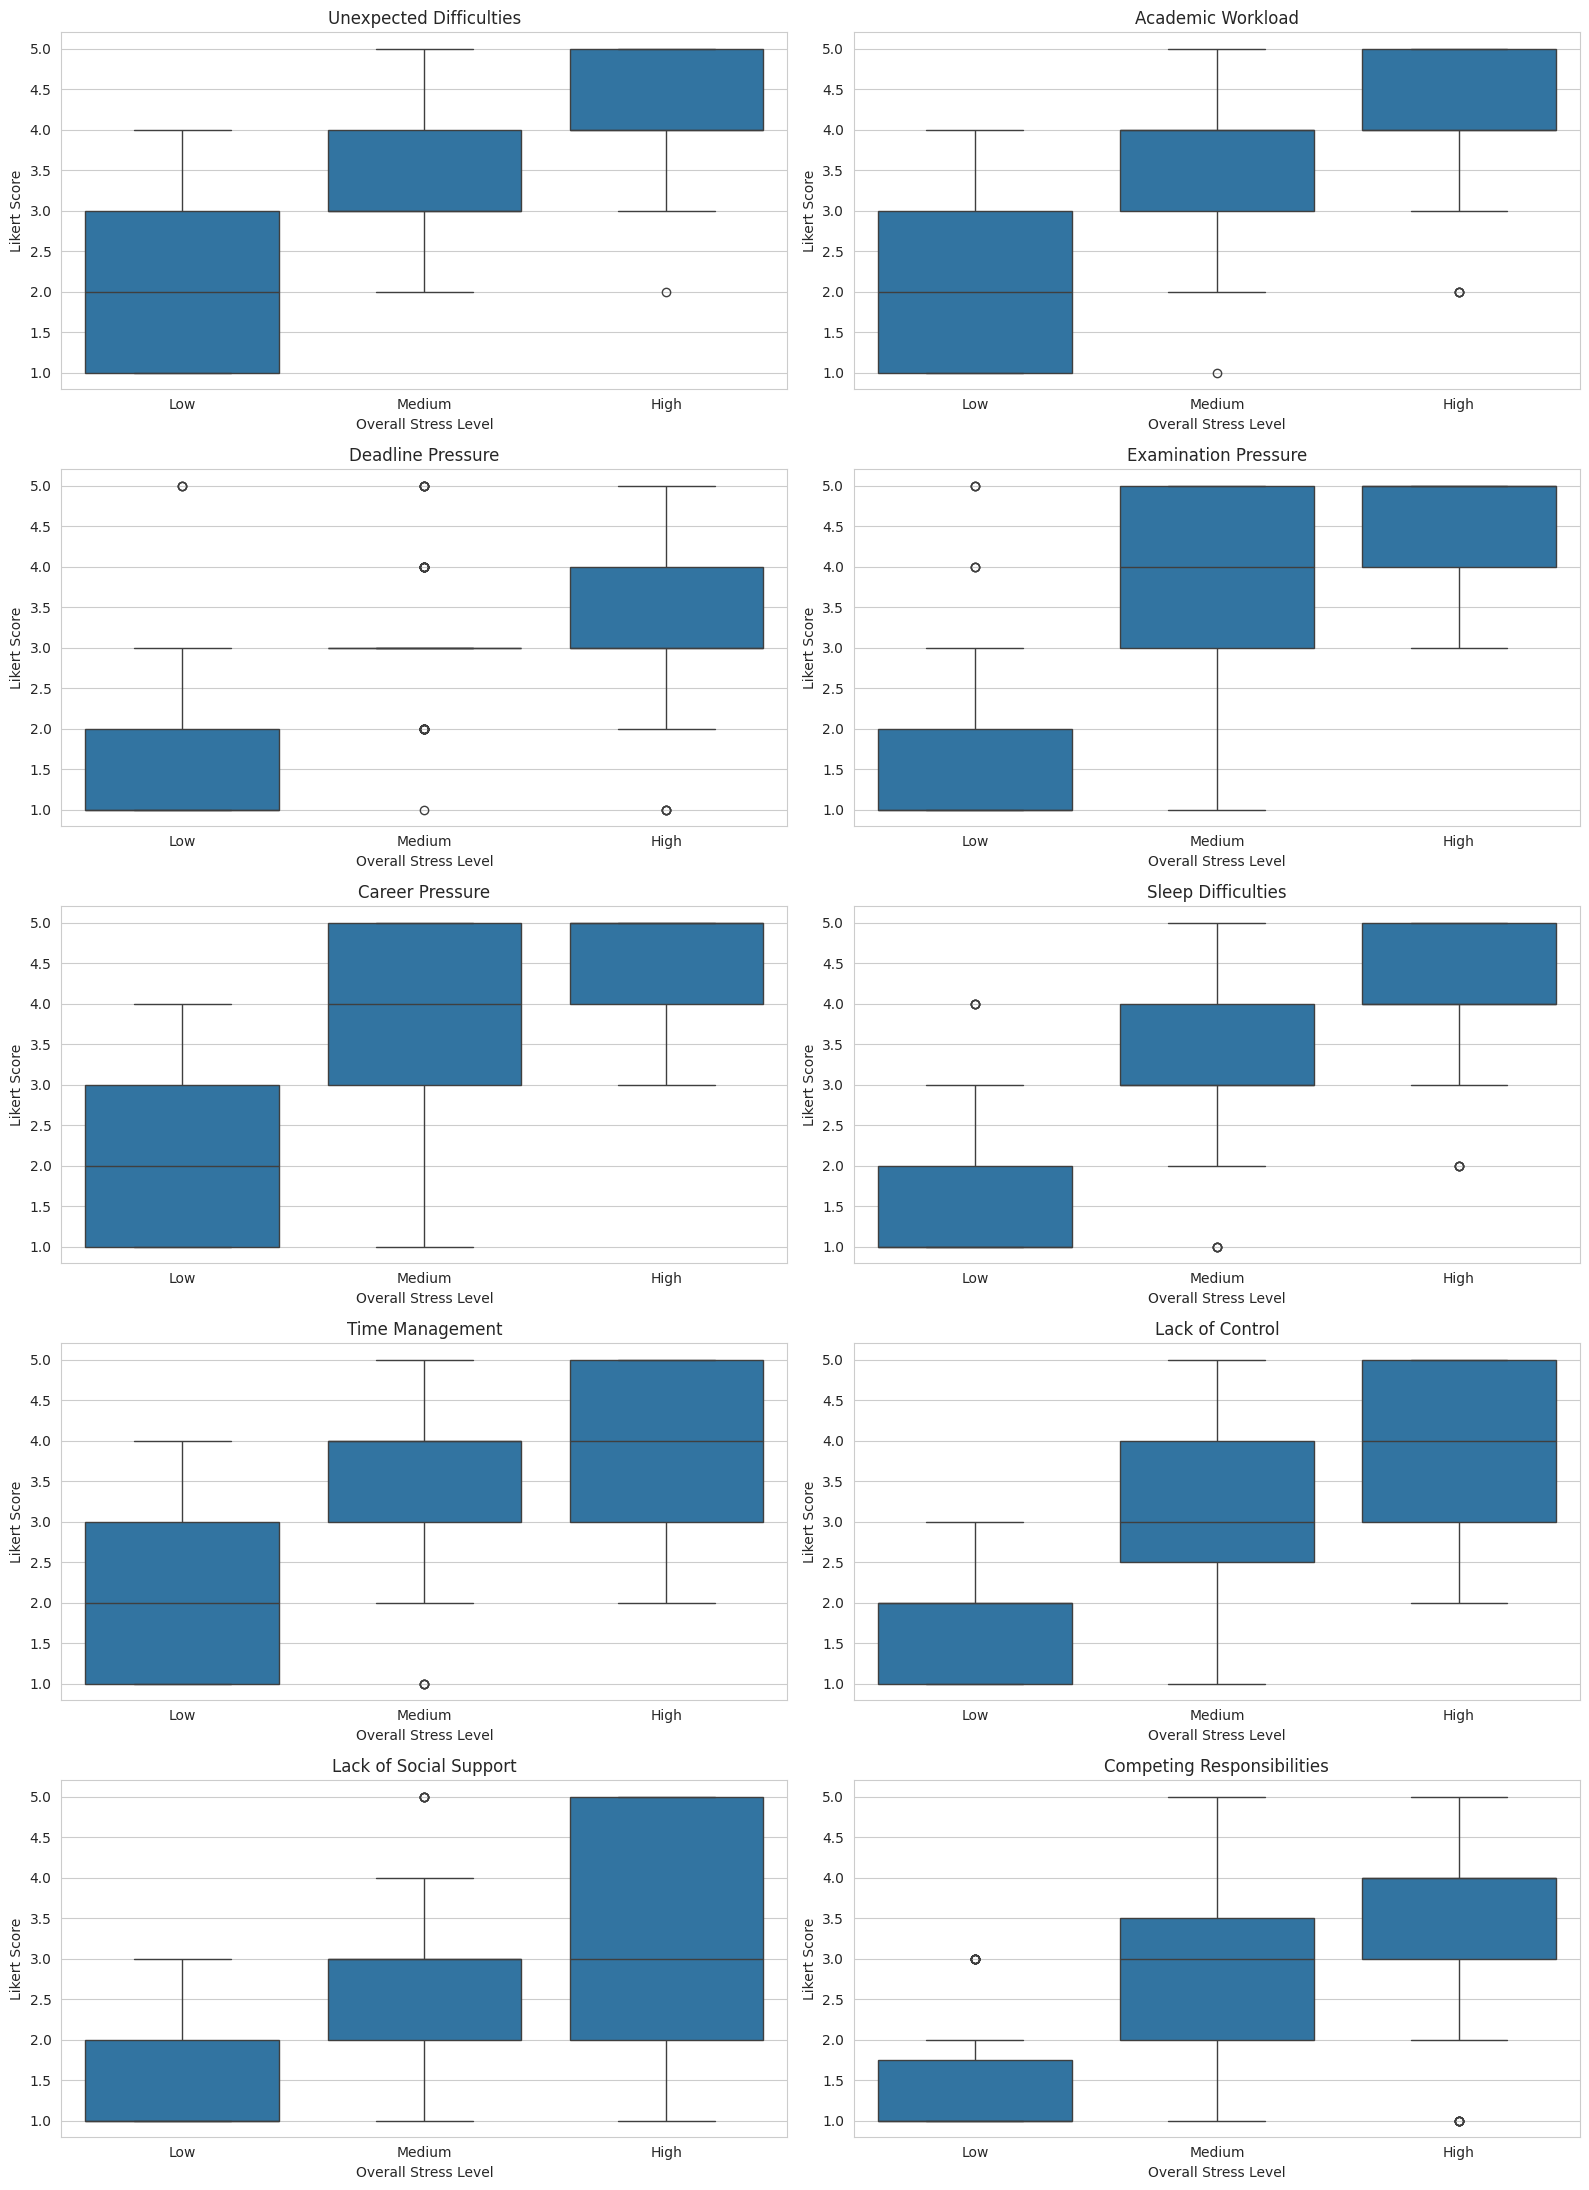

In [ ]:

fig, axes = plt.subplots(5, 2, figsize=(16, 22))

axes = axes.flatten()

for i, column in enumerate(new_feature_names):

    sns.boxplot(
        data=clean_df,
        x='Stress_Level',
        y=column,
        order=['Low', 'Medium', 'High'],
        ax=axes[i]
    )

    axes[i].set_title(column.replace('_', ' '))
    axes[i].set_xlabel("Overall Stress Level")
    axes[i].set_ylabel("Likert Score")

plt.tight_layout()
plt.show()


In [ ]:
# Calculate average feature scores for each stress category

stress_comparison = clean_df.groupby('Stress_Level')[
    new_feature_names
].mean().T

# Arrange columns in the correct order

stress_comparison = stress_comparison[
    ['Low', 'Medium', 'High']
]

display(stress_comparison.round(2))

Stress_Level,Low,Medium,High
Unexpected_Difficulties,2.09,3.57,4.18
Academic_Workload,2.15,3.57,4.06
Deadline_Pressure,1.72,3.03,3.54
Examination_Pressure,1.87,3.83,4.53
Career_Pressure,2.02,3.79,4.46
Sleep_Difficulties,1.70,3.42,4.24
Time_Management,2.09,3.53,4.14
Lack_of_Control,1.76,3.17,3.94
Lack_of_Social_Support,1.39,2.50,3.43
Competing_Responsibilities,1.50,3.07,3.46



## 20. Final Dataset Validation

After completing EDA and data preprocessing, we will perform final validation.

We will verify that:
1. All ten input features are numerical.
2. All input values lie between 1 and 5.
3. The target contains only Low, Medium and High.
4. No missing values remain.
5. The dataset contains the expected number of records and columns.

This ensures that the dataset is ready for the next phase of machine learning.


In [ ]:

# Check final dataset shape

print("Final Dataset Shape:", clean_df.shape)

# Check missing values
print("\nMissing Values:")
print(clean_df.isnull().sum())

# Check input feature data types
print("\nFeature Data Types:")
print(clean_df[new_feature_names].dtypes)

# Check target categories
print("\nTarget Categories:")
print(clean_df['Stress_Level'].unique())

# Check numerical range
print("\nMinimum Feature Value:")
print(clean_df[new_feature_names].min().min())

print("\nMaximum Feature Value:")
print(clean_df[new_feature_names].max().max())

# Display final dataset
display(clean_df.head())


Final Dataset Shape: (300, 11)

Missing Values:
Unexpected_Difficulties       0
Academic_Workload             0
Deadline_Pressure             0
Examination_Pressure          0
Career_Pressure               0
Sleep_Difficulties            0
Time_Management               0
Lack_of_Control               0
Lack_of_Social_Support        0
Competing_Responsibilities    0
Stress_Level                  0
dtype: int64

Feature Data Types:
Unexpected_Difficulties         int64
Academic_Workload               int64
Deadline_Pressure             float64
Examination_Pressure            int64
Career_Pressure                 int64
Sleep_Difficulties              int64
Time_Management               float64
Lack_of_Control               float64
Lack_of_Social_Support          int64
Competing_Responsibilities      int64
dtype: object

Target Categories:
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: string

Minimum Feature Value:
1.0

Maximum Feature Value:
5.0


,Unexpected_Difficulties,Academic_Workload,Deadline_Pressure,Examination_Pressure,Career_Pressure,Sleep_Difficulties,Time_Management,Lack_of_Control,Lack_of_Social_Support,Competing_Responsibilities,Stress_Level
0,3,4,2.0,4,5,3,4.0,2.0,1,2,Medium
1,3,3,2.0,4,4,2,3.0,2.0,2,2,Medium
2,5,3,4.0,5,4,3,4.0,3.0,2,3,High
3,5,5,5.0,5,5,5,5.0,5.0,5,5,High
4,3,4,3.0,4,4,3,3.0,2.0,2,2,High


In [ ]:

# Final validation of the cleaned dataset

# 1. Check whether the number of rows is preserved
assert clean_df.shape[0] == df.shape[0]

# 2. Check whether the number of columns is correct
assert clean_df.shape[1] == len(new_feature_names) + 1

# 3. Check for missing values
assert clean_df.isnull().sum().sum() == 0

# 4. Check whether all feature values lie between 1 and 5
assert clean_df[new_feature_names].apply(
    lambda column: column.between(1, 5).all()
).all()

# 5. Check whether target labels are available
assert clean_df['Stress_Level'].notnull().all()

# Display validation results

print("All final validation checks passed!")

print("\nFinal Dataset Information:")
print("Total Responses:", clean_df.shape[0])
print("Total Features:", len(new_feature_names))
print("Total Columns:", clean_df.shape[1])
print("Missing Values:", clean_df.isnull().sum().sum())

print("\nStress Level Distribution:")
print(clean_df['Stress_Level'].value_counts())


All final validation checks passed!

Final Dataset Information:
Total Responses: 300
Total Features: 10
Total Columns: 11
Missing Values: 0

Stress Level Distribution:
Stress_Level
Medium    127
High      127
Low        46
Name: count, dtype: Int64



## 21. Exporting the Cleaned Dataset

After completing EDA and preprocessing, we will save the cleaned dataset as a new CSV file in Google Drive.

This file will be used in the next stage of the project, which involves feature derivation, classification and model development.

The original dataset will remain unchanged.


In [ ]:

# # Save cleaned dataset to Google Drive

# output_path = '/content/drive/MyDrive/Student_Stress_Cleaned_Dataset.csv'

# clean_df.to_csv(output_path, index=False)

# print("Cleaned dataset saved successfully!")
# print("Location:", output_path)


## Creating Total Stress Score and Derived Stress Categories

We will calculate an overall stress score for each student using the ten questionnaire responses.

Each response will be converted into a numerical value from 1 to 5. The ten values will be added to calculate the total stress score.

Based on the total score, students will be assigned to Low, Medium or High stress categories.

Finally, we will compare the derived stress category with the original self-reported stress category.

In [ ]:
# Define question columns (exclude 'Stress_Level' from clean_df)
question_columns = list(clean_df.columns[:10])

for col in question_columns:
    print(f"\n{col}")
    print(clean_df[col].unique())


Unexpected_Difficulties
[3 5 4 2 1]

Academic_Workload
[4 3 5 2 1]

Deadline_Pressure
[2. 4. 5. 3. 1.]

Examination_Pressure
[4 5 3 1 2]

Career_Pressure
[5 4 3 2 1]

Sleep_Difficulties
[3 2 5 4 1]

Time_Management
[4. 3. 5. 1. 2.]

Lack_of_Control
[2. 3. 5. 4. 1.]

Lack_of_Social_Support
[1 2 5 3 4]

Competing_Responsibilities
[2 3 5 4 1]


In [ ]:
# Define Likert scale mapping

likert_mapping = {
    'Never': 1,
    'Almost Never': 2,
    'Sometimes': 3,
    'Fairly Often': 4,
    'Very Often': 5
}

# Select Q1 to Q10 (exclude Timestamp and Stress_Level)
question_columns = list(clean_df.columns[:10])

# Ensure all questionnaire responses are numeric
numeric_scores = clean_df[question_columns].apply(
    pd.to_numeric, errors='coerce'
)

# Handle missing values using column median
numeric_scores = numeric_scores.fillna(numeric_scores.median())

display(numeric_scores.head())

,Academic_Workload,Deadline_Pressure,Examination_Pressure,Career_Pressure,Sleep_Difficulties,Time_Management,Lack_of_Control,Lack_of_Social_Support,Competing_Responsibilities
0,4,2.0,4,5,3,4.0,2.0,1,2
1,3,2.0,4,4,2,3.0,2.0,2,2
2,3,4.0,5,4,3,4.0,3.0,2,3
3,5,5.0,5,5,5,5.0,5.0,5,5
4,4,3.0,4,4,3,3.0,2.0,2,2


In [ ]:
# Calculate total score using all ten questions

clean_df['Total_Stress_Score'] = numeric_scores.sum(axis=1)

display(clean_df[['Total_Stress_Score']].head())

,Total_Stress_Score
0,27.0
1,24.0
2,31.0
3,45.0
4,27.0


In [ ]:
# Define score-based stress categories

def classify_stress(score):

    if 10 <= score <= 23:
        return 'Low'

    elif 24 <= score <= 36:
        return 'Medium'

    elif 37 <= score <= 50:
        return 'High'

    else:
        return 'Invalid'

# Create score-based label

clean_df['Score_Based_Label'] = clean_df['Total_Stress_Score'].apply(
    classify_stress
)

display(clean_df[['Total_Stress_Score', 'Score_Based_Label']].head())

,Total_Stress_Score,Score_Based_Label
0,27.0,Medium
1,24.0,Medium
2,31.0,Medium
3,45.0,High
4,27.0,Medium


In [ ]:
# Identify original target column

original_target = clean_df.columns[10]

# Compare original and score-based labels

clean_df['Final_Label'] = np.where(
    clean_df[original_target].astype(str).str.strip().str.title()
    == clean_df['Score_Based_Label'],

    clean_df[original_target],

    clean_df['Score_Based_Label']
)

# Display comparison

display(clean_df[[
    original_target,
    'Total_Stress_Score',
    'Score_Based_Label',
    'Final_Label'
]].head(100))

,Stress_Level,Total_Stress_Score,Score_Based_Label,Final_Label
0,Medium,27.0,Medium,Medium
1,Medium,24.0,Medium,Medium
2,High,31.0,Medium,Medium
3,High,45.0,High,High
4,High,27.0,Medium,Medium
...,...,...,...,...
95,High,29.0,Medium,Medium
96,High,41.0,High,High
97,Low,30.0,Medium,Medium
98,Medium,28.0,Medium,Medium


In [ ]:
# Compare original and derived labels

match_count = (
    clean_df[original_target].astype(str).str.strip().str.title()
    == clean_df['Score_Based_Label']
).sum()

mismatch_count = len(df) - match_count

print("Matching Labels:", match_count)
print("Mismatching Labels:", mismatch_count)

print("Matching Percentage:", round(match_count / len(df) * 100, 2), "%")

Matching Labels: 193
Mismatching Labels: 107
Matching Percentage: 64.33 %


In [ ]:
# Save updated dataset

output_path = '/content/drive/MyDrive/Student_Academic_Stress_With_Scores.csv'

clean_df.to_csv(output_path, index=False)

print("Updated dataset saved successfully!")
print("Total columns:", clean_df.shape[1])
print("Total responses:", clean_df.shape[0])

Updated dataset saved successfully!
Total columns: 14
Total responses: 300


## Creating the Final Dataset for Further Analysis

We will retain the Timestamp, ten questionnaire features and the Final_Label column.

The original columns containing the self-reported stress level, total stress score and score-based label will be excluded.

The Final_Label column will be renamed as Stress_Level for further analysis.

In [ ]:

# Select columns A-K and O

df_final = clean_df.iloc[:, :11].copy()

# Add original column O (Final_Label) as the last column
df_final['Stress_Level'] = clean_df['Final_Label']

# Display final dataset
display(df_final.head())

# Check dimensions
print("Final Dataset Shape:", df_final.shape)
print("Total Rows:", df_final.shape[0])
print("Total Columns:", df_final.shape[1])

# Display column names
print("\nFinal Column Names:")
print(df_final.columns.tolist())


,Unexpected_Difficulties,Academic_Workload,Deadline_Pressure,Examination_Pressure,Career_Pressure,Sleep_Difficulties,Time_Management,Lack_of_Control,Lack_of_Social_Support,Competing_Responsibilities,Stress_Level
0,3,4,2.0,4,5,3,4.0,2.0,1,2,Medium
1,3,3,2.0,4,4,2,3.0,2.0,2,2,Medium
2,5,3,4.0,5,4,3,4.0,3.0,2,3,Medium
3,5,5,5.0,5,5,5,5.0,5.0,5,5,High
4,3,4,3.0,4,4,3,3.0,2.0,2,2,Medium


Final Dataset Shape: (300, 11)
Total Rows: 300
Total Columns: 11

Final Column Names:
['Unexpected_Difficulties', 'Academic_Workload', 'Deadline_Pressure', 'Examination_Pressure', 'Career_Pressure', 'Sleep_Difficulties', 'Time_Management', 'Lack_of_Control', 'Lack_of_Social_Support', 'Competing_Responsibilities', 'Stress_Level']


In [ ]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# df_final = pd.read_csv(
#     '/content/drive/MyDrive/Student_Academic_Stress_With_Scores.csv'
# )

# print("Dataset Shape:", df_final.shape)

# display(df_final.head())

In [ ]:
# Input features: all ten questionnaire questions (exclude Timestamp/target)
X = df_final.iloc[:, :10].copy()

# Target: final stress category

y = df_final['Stress_Level'].copy()

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Input Features Shape: (300, 10)
Target Shape: (300,)

Target Distribution:
Stress_Level
Medium     186
High        63
Low         46
Invalid      5
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))

Training Samples: 240
Testing Samples: 60

Training Class Distribution:
Stress_Level
Medium     0.620833
High       0.208333
Low        0.154167
Invalid    0.016667
Name: proportion, dtype: float64

Testing Class Distribution:
Stress_Level
Medium     0.616667
High       0.216667
Low        0.150000
Invalid    0.016667
Name: proportion, dtype: float64


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation Ready!")


## Random Forest Model Implementation

In this section, we will implement a Random Forest Classifier to predict students' academic stress levels using the ten questionnaire features.


In [ ]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")


All libraries imported successfully!



## Preparing Input Features and Target Variable

We will use the ten questionnaire responses as input features (X) and the original self-reported stress category as the target variable (y).

The Likert responses will be converted into numerical values from 1 to 5.


In [ ]:

# Define Likert scale mapping

likert_mapping = {
    'Never': 1,
    'Almost Never': 2,
    'Sometimes': 3,
    'Fairly Often': 4,
    'Very Often': 5
}

# Select the original ten questionnaire features
X = df.iloc[:, 1:11].copy()

# Convert responses into numerical values
for column in X.columns:
    X[column] = (
        X[column]
        .astype('string')
        .str.strip()
        .map(likert_mapping)
    )

# Rename input features
X.columns = new_feature_names

# Select original self-reported target
original_target_column = df.columns[11]

y = (
    df[original_target_column]
    .astype('string')
    .str.strip()
    .str.title()
)

# Display information

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nMissing Input Values:", X.isnull().sum().sum())


Input Features Shape: (300, 10)
Target Shape: (300,)

Target Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
Medium    127
High      127
Low        46
Name: count, dtype: Int64

Missing Input Values: 3



## Train-Test Split

We will split the dataset into 80% training data and 20% testing data.

Stratified sampling will maintain approximately the same class distribution in both sets. The testing data will remain untouched during model training and tuning.


In [ ]:

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())


Training Samples: 240
Testing Samples: 60

Training Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
Medium    102
High      101
Low        37
Name: count, dtype: Int64

Testing Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
High      26
Medium    25
Low        9
Name: count, dtype: Int64



## Stratified 5-Fold Cross-Validation

We will use Stratified 5-Fold Cross-Validation to evaluate the model across five different data splits while maintaining class proportions in each fold.


In [ ]:

# Initialize cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation initialized!")


Stratified 5-Fold Cross-Validation initialized!



## Initial Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple Decision Trees to make predictions.

We will first train a baseline model using default hyperparameters and balanced class weights.




In [ ]:

# Create initial Random Forest pipeline

initial_rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),

    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model

initial_rf_pipeline.fit(X_train, y_train)

# Generate predictions

initial_predictions = initial_rf_pipeline.predict(X_test)

print("Initial Random Forest Model Trained Successfully!")


Initial Random Forest Model Trained Successfully!



## Initial Model Performance

We will evaluate the initial model using Accuracy, Macro Precision, Macro Recall and Macro F1-score.


In [ ]:

# Calculate initial performance

initial_accuracy = accuracy_score(
    y_test, initial_predictions
)

initial_precision = precision_score(
    y_test, initial_predictions,
    average='macro',
    zero_division=0
)

initial_recall = recall_score(
    y_test, initial_predictions,
    average='macro',
    zero_division=0
)

initial_f1 = f1_score(
    y_test, initial_predictions,
    average='macro',
    zero_division=0
)

# Display results

print("INITIAL RANDOM FOREST PERFORMANCE")
print("----------------------------------")

print("Accuracy:", round(initial_accuracy, 4))
print("Precision:", round(initial_precision, 4))
print("Recall:", round(initial_recall, 4))
print("Macro F1-Score:", round(initial_f1, 4))


INITIAL RANDOM FOREST PERFORMANCE
----------------------------------
Accuracy: 0.85
Precision: 0.9118
Recall: 0.8604
Macro F1-Score: 0.8689



## Hyperparameter Tuning

We will tune three important Random Forest hyperparameters:

- n_estimators: Number of Decision Trees.
- max_depth: Maximum depth of each tree.
- min_samples_leaf: Minimum samples required at a leaf node.

Grid Search will test different combinations to identify the best configuration.


In [ ]:

# Define hyperparameter grid

param_grid = {
    'classifier__n_estimators': [100, 200, 300],

    'classifier__max_depth': [None, 5, 10, 15],

    'classifier__min_samples_leaf': [1, 2, 4]
}

print("Hyperparameter Grid:")
print(param_grid)

total_combinations = (
    len(param_grid['classifier__n_estimators']) *
    len(param_grid['classifier__max_depth']) *
    len(param_grid['classifier__min_samples_leaf'])
)

print("\nTotal Combinations:", total_combinations)


Hyperparameter Grid:
{'classifier__n_estimators': [100, 200, 300], 'classifier__max_depth': [None, 5, 10, 15], 'classifier__min_samples_leaf': [1, 2, 4]}

Total Combinations: 36



## Grid Search with Stratified Cross-Validation

We will use GridSearchCV with Stratified 5-Fold Cross-Validation.

Macro F1-score will be the primary scoring metric. Tuning will be performed only on the training dataset.


In [ ]:

# Create Random Forest pipeline

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),

    ('classifier', RandomForestClassifier(
        class_weight='balanced',
        random_state=42
    ))
])

# Initialize GridSearchCV

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Perform hyperparameter tuning

grid_search.fit(X_train, y_train)

print("\nHyperparameter tuning completed successfully!")


Fitting 5 folds for each of 36 candidates, totalling 180 fits

Hyperparameter tuning completed successfully!



## Best Hyperparameters and Cross-Validation Score

We will identify the best hyperparameter combination and its corresponding cross-validation Macro F1-score.


In [ ]:

# Get best parameters and score

best_params = grid_search.best_params_
best_cv_score = grid_search.best_score_

print("BEST RANDOM FOREST MODEL")
print("-------------------------")

print("\nBest Hyperparameters:")

for parameter, value in best_params.items():
    print(parameter, ":", value)

print("\nBest CV Macro F1-Score:",
      round(best_cv_score, 4))


BEST RANDOM FOREST MODEL
-------------------------

Best Hyperparameters:
classifier__max_depth : 15
classifier__min_samples_leaf : 1
classifier__n_estimators : 100

Best CV Macro F1-Score: 0.8775



## Selecting the Best Random Forest Model

GridSearchCV automatically refits the best configuration using the complete training dataset. We will retrieve this fitted pipeline for final evaluation.


In [ ]:

# Retrieve best fitted model

best_rf_model = grid_search.best_estimator_

print("Best Random Forest Model Selected Successfully!")

print("\nSelected Model:")
print(best_rf_model)


Best Random Forest Model Selected Successfully!

Selected Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=15,
                                        random_state=42))])



## Final Predictions

We will use the optimized Random Forest model to predict stress categories on the untouched testing dataset.


In [ ]:

# Generate predictions

y_pred = best_rf_model.predict(X_test)

print("Final predictions generated successfully!")

# Compare actual and predicted values

comparison = pd.DataFrame({
    'Actual Stress Level': y_test.values,
    'Predicted Stress Level': y_pred
})

display(comparison.head(10))


Final predictions generated successfully!


,Actual Stress Level,Predicted Stress Level
0,Medium,Medium
1,Medium,Medium
2,High,High
3,High,High
4,High,High
5,Low,Low
6,High,High
7,High,High
8,Medium,Medium
9,Medium,Medium



## Final Random Forest Performance

We will evaluate the optimized model using Accuracy, Macro Precision, Macro Recall and Macro F1-score on the testing dataset.


In [ ]:

# Calculate final performance metrics

final_accuracy = accuracy_score(y_test, y_pred)

final_precision = precision_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

final_recall = recall_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

final_f1 = f1_score(
    y_test, y_pred,
    average='macro',
    zero_division=0
)

# Display results

print("FINAL RANDOM FOREST PERFORMANCE")
print("--------------------------------")

print("Test Accuracy:", round(final_accuracy, 4))
print("Test Precision:", round(final_precision, 4))
print("Test Recall:", round(final_recall, 4))
print("Test Macro F1-Score:", round(final_f1, 4))


FINAL RANDOM FOREST PERFORMANCE
--------------------------------
Test Accuracy: 0.8667
Test Precision: 0.9192
Test Recall: 0.8732
Test Macro F1-Score: 0.8826



## Initial vs Tuned Model Comparison

We will compare the performance of the initial and tuned Random Forest models to understand the impact of hyperparameter tuning.


In [ ]:

# Create comparison table

performance_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-Score'
    ],

    'Initial Model': [
        initial_accuracy,
        initial_precision,
        initial_recall,
        initial_f1
    ],

    'Tuned Model': [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

display(performance_comparison.round(4))


,Metric,Initial Model,Tuned Model
0,Accuracy,0.8500,0.8667
1,Macro Precision,0.9118,0.9192
2,Macro Recall,0.8604,0.8732
3,Macro F1-Score,0.8689,0.8826



## Confusion Matrix

The confusion matrix compares actual and predicted stress categories and helps identify correct and incorrect classifications.


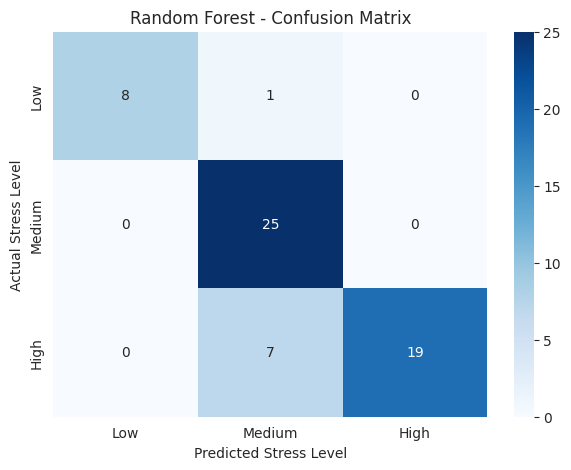

In [ ]:

# Generate confusion matrix

class_labels = ['Low', 'Medium', 'High']

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_labels
)

# Visualize confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")

plt.show()



## Classification Report

The classification report provides Precision, Recall, F1-score and Support for each stress category: Low, Medium and High.


In [ ]:

# Generate classification report

report = classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    target_names=class_labels,
    zero_division=0
)

print("RANDOM FOREST CLASSIFICATION REPORT")
print("-----------------------------------")

print(report)


RANDOM FOREST CLASSIFICATION REPORT
-----------------------------------
              precision    recall  f1-score   support

         Low       1.00      0.89      0.94         9
      Medium       0.76      1.00      0.86        25
        High       1.00      0.73      0.84        26

    accuracy                           0.87        60
   macro avg       0.92      0.87      0.88        60
weighted avg       0.90      0.87      0.87        60




## Random Forest Results Summary

This section summarizes the initial model performance, best hyperparameters, cross-validation score and final testing metrics.


In [ ]:

# Create final results summary

rf_results = pd.DataFrame({
    'Parameter': [
        'Initial Accuracy',
        'Initial Macro F1',
        'Best Hyperparameters',
        'Best CV Macro F1',
        'Final Test Accuracy',
        'Final Test Precision',
        'Final Test Recall',
        'Final Test Macro F1'
    ],

    'Value': [
        round(initial_accuracy, 4),
        round(initial_f1, 4),
        str(best_params),
        round(best_cv_score, 4),
        round(final_accuracy, 4),
        round(final_precision, 4),
        round(final_recall, 4),
        round(final_f1, 4)
    ]
})

display(rf_results)


,Parameter,Value
0,Initial Accuracy,0.85
1,Initial Macro F1,0.8689
2,Best Hyperparameters,"{'classifier__max_depth': 15, 'classifier__min..."
3,Best CV Macro F1,0.8775
4,Final Test Accuracy,0.8667
5,Final Test Precision,0.9192
6,Final Test Recall,0.8732
7,Final Test Macro F1,0.8826


## Logistic Regression Model Implementation

In this section, we will implement  Logistic Regression to predict students' academic stress levels using the ten questionnaire features.

In [ ]:

# Import required libraries

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

from sklearn.linear_model import LogisticRegression

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")


Libraries imported successfully!


## Separate input features and target variable

In [ ]:

# Independent variables
X = clean_df[new_feature_names]

# Dependent variable
y = clean_df['Stress_Level']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


Features shape: (300, 10)
Target shape: (300,)

Target distribution:
Stress_Level
Medium    127
High      127
Low        46
Name: count, dtype: Int64


## Split the dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 240
Testing samples: 60

Training target distribution:
Stress_Level
Medium    102
High      101
Low        37
Name: count, dtype: Int64

Testing target distribution:
Stress_Level
High      26
Medium    25
Low        9
Name: count, dtype: Int64


## Build the initial Logistic Regression model

In [ ]:

# Create a pipeline

initial_model = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=2000))
])

# Train the initial model
initial_model.fit(X_train, y_train)

# Make predictions
y_pred_initial = initial_model.predict(X_test)

# Evaluate the model
initial_accuracy = accuracy_score(y_test, y_pred_initial)

initial_macro_f1 = f1_score(
    y_test,
    y_pred_initial,
    average='macro'
)

print("Initial Logistic Regression Performance")
print("---------------------------------------")
print("Accuracy:", round(initial_accuracy, 4))
print("Macro F1-score:", round(initial_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_initial))


Initial Logistic Regression Performance
---------------------------------------
Accuracy: 0.7167
Macro F1-score: 0.7432

Classification Report:
              precision    recall  f1-score   support

        High       0.77      0.65      0.71        26
         Low       0.80      0.89      0.84         9
      Medium       0.64      0.72      0.68        25

    accuracy                           0.72        60
   macro avg       0.74      0.75      0.74        60
weighted avg       0.72      0.72      0.72        60



## Hyperparameter Tuning

here we define  hyperparameter combinations and Stratified 5-Fold Cross Validation



In [ ]:

# Define hyperparameter grid

param_grid = {
    'logistic__C': [0.01, 0.1, 1, 10, 100],
    'logistic__penalty': ['l1', 'l2']
}

# Define Stratified 5-Fold Cross Validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Hyperparameter grid defined successfully!")


Hyperparameter grid defined successfully!


We are testing:
- 5 values of C.
- 2 types of penalty.
- 10 total combinations.
- 5 cross-validation folds.
Therefore, GridSearchCV will perform 50 model fits

## Perform hyperparameter tuning

In [ ]:

# Create Logistic Regression pipeline

logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        solver='saga',
        max_iter=5000,
        random_state=42
    ))
])

# Create GridSearchCV

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning
grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Hyperparameter tuning completed!


## Display best hyperparameters


In [ ]:
print("Best Hyperparameters:")
print("----------------------")

print("Best C:", grid_search.best_params_['logistic__C'])

print("Best Penalty:", grid_search.best_params_['logistic__penalty'])


Best Hyperparameters:
----------------------
Best C: 0.01
Best Penalty: l2


## Display the best cross-validation Macro F1-score

In [ ]:
best_cv_score = grid_search.best_score_

print("Best Cross-Validation Macro F1-score:",
      round(best_cv_score, 4))


Best Cross-Validation Macro F1-score: 0.7102


## Calculate final test Accuracy, Precision, Recall and Macro F1-score


In [ ]:

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict using the best tuned model
best_model = grid_search.best_estimator_
y_pred_final = best_model.predict(X_test)

# Calculate final test metrics

final_accuracy = accuracy_score(y_test, y_pred_final)

final_precision = precision_score(
    y_test, y_pred_final, average='macro', zero_division=0
)

final_recall = recall_score(
    y_test, y_pred_final, average='macro', zero_division=0
)

final_macro_f1 = f1_score(
    y_test, y_pred_final, average='macro', zero_division=0
)

# Display results

print("FINAL LOGISTIC REGRESSION PERFORMANCE")
print("=" * 45)

print("Test Accuracy:", round(final_accuracy, 4))
print("Test Precision:", round(final_precision, 4))
print("Test Recall:", round(final_recall, 4))
print("Test Macro F1-score:", round(final_macro_f1, 4))


FINAL LOGISTIC REGRESSION PERFORMANCE
Test Accuracy: 0.7667
Test Precision: 0.8271
Test Recall: 0.7695
Test Macro F1-score: 0.7919


## Confusion Matrix

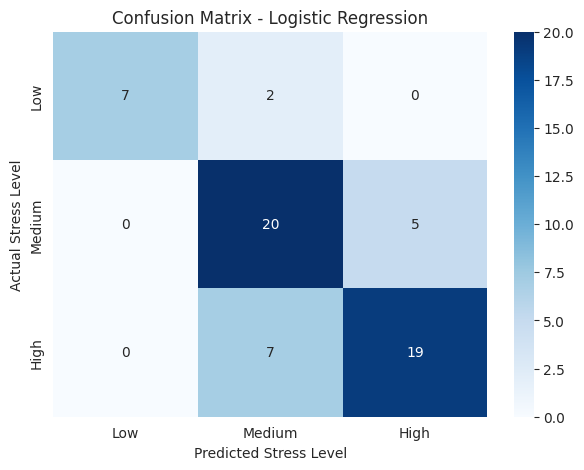

In [ ]:

from sklearn.metrics import confusion_matrix

# Define class order

class_labels = ['Low', 'Medium', 'High']

# Calculate confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=class_labels
)

# Plot confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")

plt.show()


## Classification report.

In [ ]:

from sklearn.metrics import classification_report

# Generate classification report

report = classification_report(
    y_test,
    y_pred_final,
    labels=class_labels,
    target_names=class_labels,
    zero_division=0
)

print("CLASSIFICATION REPORT")
print("=" * 45)

print(report)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       1.00      0.78      0.88         9
      Medium       0.69      0.80      0.74        25
        High       0.79      0.73      0.76        26

    accuracy                           0.77        60
   macro avg       0.83      0.77      0.79        60
weighted avg       0.78      0.77      0.77        60



## final performance summary table

In [ ]:

# Create final performance summary

final_results = pd.DataFrame({
    'Evaluation Metric': [
        'Test Accuracy',
        'Test Precision (Macro)',
        'Test Recall (Macro)',
        'Test Macro F1-score'
    ],

    'Logistic Regression': [
        final_accuracy,
        final_precision,
        final_recall,
        final_macro_f1
    ]
})

display(final_results.round(4))


,Evaluation Metric,Logistic Regression
0,Test Accuracy,0.7667
1,Test Precision (Macro),0.8271
2,Test Recall (Macro),0.7695
3,Test Macro F1-score,0.7919



### Preparing the Tuned Logistic Regression Model

The Logistic Regression pipeline was found to be unfitted in the current notebook session.

Therefore, we will configure it using the best hyperparameters obtained during the individual model implementation and fit it using the training dataset.

The pipeline includes StandardScaler for feature scaling and Logistic Regression for classification.

The test dataset will remain untouched during training.


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.utils.validation import check_is_fitted

# Redefine the logistic regression pipeline to include median imputation for handling missing values
logistic_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('logistic', LogisticRegression(
        solver='saga',
        max_iter=5000,
        random_state=42
    ))
])

# Configure Logistic Regression using the best hyperparameters
logistic_pipeline.set_params(
    logistic__C=0.01,
    logistic__penalty='l2'
)

# Fit the pipeline using training data only
logistic_pipeline.fit(X_train, y_train)

# Verify whether the model is fitted
check_is_fitted(logistic_pipeline)

print("Logistic Regression pipeline fitted successfully!")
print("Classes:", logistic_pipeline.classes_)

Logistic Regression pipeline fitted successfully!
Classes: ['High' 'Low' 'Medium']


## KNN Model Implementation

In this section, we will implement  KNN to predict students' academic stress levels using the ten questionnaire features.

In [ ]:
# Import required libraries

from sklearn.neighbors import KNeighborsClassifier

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("KNN libraries imported successfully!")

KNN libraries imported successfully!


## Initial KNN model performance

In [ ]:
# Create initial KNN pipeline

initial_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Train initial KNN model

initial_knn.fit(X_train, y_train)

# Predict test data

y_pred_knn_initial = initial_knn.predict(X_test)

# Calculate initial performance

initial_knn_accuracy = accuracy_score(
    y_test, y_pred_knn_initial
)

initial_knn_macro_f1 = f1_score(
    y_test, y_pred_knn_initial, average='macro'
)

# Display results

print("INITIAL KNN MODEL PERFORMANCE")
print("=" * 40)

print("Initial Accuracy:",
      round(initial_knn_accuracy, 4))

print("Initial Macro F1-score:",
      round(initial_knn_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn_initial))

INITIAL KNN MODEL PERFORMANCE
Initial Accuracy: 0.8167
Initial Macro F1-score: 0.8173

Classification Report:
              precision    recall  f1-score   support

        High       0.95      0.73      0.83        26
         Low       0.69      1.00      0.82         9
      Medium       0.78      0.84      0.81        25

    accuracy                           0.82        60
   macro avg       0.81      0.86      0.82        60
weighted avg       0.84      0.82      0.82        60



In [ ]:
# Prepare input features from the encoded dataset

X = df_encoded.iloc[:, 1:11].copy()

# Assign meaningful feature names
X.columns = new_feature_names

# Prepare target variable
y = df[target_column].astype(str).str.strip().str.title()

# Display the input features and target
print("Input Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

display(X.head())


Input Feature Shape: (300, 10)
Target Shape: (300,)

Target Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
Medium    127
High      127
Low        46
Name: count, dtype: int64


,Unexpected_Difficulties,Academic_Workload,Deadline_Pressure,Examination_Pressure,Career_Pressure,Sleep_Difficulties,Time_Management,Lack_of_Control,Lack_of_Social_Support,Competing_Responsibilities
0,3,4,2.0,4,5,3,4.0,2.0,1,2
1,3,3,2.0,4,4,2,3.0,2.0,2,2
2,5,3,4.0,5,4,3,4.0,3.0,2,3
3,5,5,5.0,5,5,5,5.0,5.0,5,5
4,3,4,3.0,4,4,3,3.0,2.0,2,2


In [ ]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())


Training Features: (240, 10)
Testing Features: (60, 10)

Training Target Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
Medium    102
High      101
Low        37
Name: count, dtype: int64

Testing Target Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
High      26
Medium    25
Low        9
Name: count, dtype: int64


In [ ]:

# Create initial KNN pipeline

knn_initial = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Train the initial model
knn_initial.fit(X_train, y_train)

# Predict on test data
y_pred_initial = knn_initial.predict(X_test)

print("Initial KNN Model Trained Successfully!")


Initial KNN Model Trained Successfully!


In [ ]:

# Calculate initial model performance

initial_accuracy = accuracy_score(y_test, y_pred_initial)

initial_precision = precision_score(
    y_test, y_pred_initial, average='macro', zero_division=0
)

initial_recall = recall_score(
    y_test, y_pred_initial, average='macro', zero_division=0
)

initial_f1 = f1_score(
    y_test, y_pred_initial, average='macro', zero_division=0
)

# Display initial performance

initial_results = pd.DataFrame({
    'Metric': ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-score'],
    'Initial KNN': [
        initial_accuracy,
        initial_precision,
        initial_recall,
        initial_f1
    ]
})

display(initial_results.round(4))


,Metric,Initial KNN
0,Accuracy,0.8167
1,Macro Precision,0.8067
2,Macro Recall,0.8569
3,Macro F1-score,0.8173


In [ ]:

# Define hyperparameter combinations

param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 13],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

print("Hyperparameter combinations:",
      len(param_grid['knn__n_neighbors']) *
      len(param_grid['knn__weights']) *
      len(param_grid['knn__p']))


Hyperparameter combinations: 24


In [ ]:

# Define Stratified 5-Fold Cross-Validation

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


In [ ]:

# Initialize GridSearchCV

grid_search = GridSearchCV(
    estimator=knn_initial,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Perform hyperparameter tuning

grid_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")


Fitting 5 folds for each of 24 candidates, totalling 120 fits
Hyperparameter tuning completed!


In [ ]:

# Get the best hyperparameters

best_params = grid_search.best_params_

# Get the best cross-validation Macro F1-score

best_cv_f1 = grid_search.best_score_

print("Best Hyperparameters:")
print(best_params)

print("\nBest Cross-Validation Macro F1-score:")
print(round(best_cv_f1, 4))


Best Hyperparameters:
{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}

Best Cross-Validation Macro F1-score:
0.9049


In [ ]:

# Retrieve the best tuned model

best_knn_model = grid_search.best_estimator_

# Predict stress categories on test data

y_pred = best_knn_model.predict(X_test)

print("Final tuned KNN predictions generated!")


Final tuned KNN predictions generated!


In [ ]:
# Compare actual and predicted values

knn_comparison = pd.DataFrame({
    'Actual Stress Level': y_test.values,
    'Predicted Stress Level': y_pred
})

# Add prediction correctness
knn_comparison['Prediction Status'] = np.where(
    knn_comparison['Actual Stress Level'] ==
    knn_comparison['Predicted Stress Level'],
    'Correct',
    'Incorrect'
)

display(knn_comparison)

,Actual Stress Level,Predicted Stress Level,Prediction Status
0,Medium,Medium,Correct
1,Medium,Medium,Correct
2,High,Medium,Incorrect
3,High,High,Correct
4,High,High,Correct
5,Low,Low,Correct
6,High,High,Correct
7,High,High,Correct
8,Medium,Medium,Correct
9,Medium,Medium,Correct


In [ ]:
# Count correct and incorrect predictions

print("Correct Predictions:",
      (knn_comparison['Prediction Status'] == 'Correct').sum())

print("Incorrect Predictions:",
      (knn_comparison['Prediction Status'] == 'Incorrect').sum())

Correct Predictions: 53
Incorrect Predictions: 7


In [ ]:
# Display incorrectly classified observations

incorrect_predictions = knn_comparison[
    knn_comparison['Prediction Status'] == 'Incorrect'
]

display(incorrect_predictions)

,Actual Stress Level,Predicted Stress Level,Prediction Status
2,High,Medium,Incorrect
23,Medium,Low,Incorrect
27,High,Medium,Incorrect
31,High,Medium,Incorrect
41,High,Medium,Incorrect
53,High,Medium,Incorrect
58,High,Medium,Incorrect


In [ ]:

# Calculate final test performance

final_accuracy = accuracy_score(y_test, y_pred)

final_precision = precision_score(
    y_test, y_pred, average='macro', zero_division=0
)

final_recall = recall_score(
    y_test, y_pred, average='macro', zero_division=0
)

final_f1 = f1_score(
    y_test, y_pred, average='macro', zero_division=0
)

# Display final evaluation results

final_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-score'
    ],
    'Final Tuned KNN': [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

display(final_results.round(4))


,Metric,Final Tuned KNN
0,Accuracy,0.8833
1,Macro Precision,0.9000
2,Macro Recall,0.9097
3,Macro F1-score,0.8966


In [ ]:

# Compare initial and tuned KNN performance

comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-score'
    ],
    'Initial KNN': [
        initial_accuracy,
        initial_precision,
        initial_recall,
        initial_f1
    ],
    'Tuned KNN': [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

display(comparison.round(4))


,Metric,Initial KNN,Tuned KNN
0,Accuracy,0.8167,0.8833
1,Macro Precision,0.8067,0.9000
2,Macro Recall,0.8569,0.9097
3,Macro F1-score,0.8173,0.8966


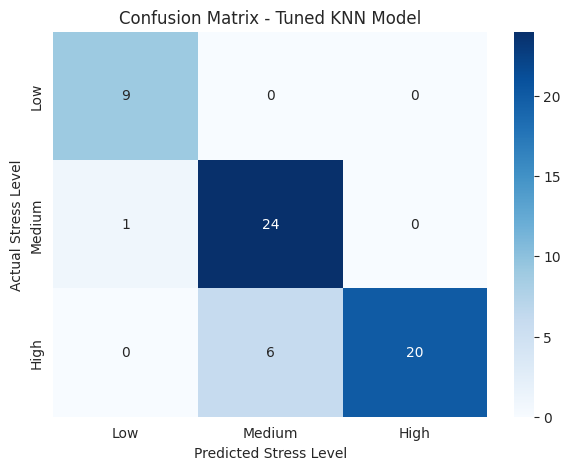

In [ ]:

# Generate confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High']
)

# Visualize confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title("Confusion Matrix - Tuned KNN Model")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")

plt.show()


In [ ]:

# Generate classification report

report = classification_report(
    y_test,
    y_pred,
    labels=['Low', 'Medium', 'High'],
    target_names=['Low Stress', 'Medium Stress', 'High Stress'],
    zero_division=0
)

print("Classification Report - Tuned KNN Model\n")
print(report)


Classification Report - Tuned KNN Model

               precision    recall  f1-score   support

   Low Stress       0.90      1.00      0.95         9
Medium Stress       0.80      0.96      0.87        25
  High Stress       1.00      0.77      0.87        26

     accuracy                           0.88        60
    macro avg       0.90      0.91      0.90        60
 weighted avg       0.90      0.88      0.88        60



In [ ]:

# Final KNN model summary

print("\n1. INITIAL MODEL PERFORMANCE")
print(initial_results.to_string(index=False))
print("\n2. BEST HYPERPARAMETERS")
print(best_params)
print("\n3. BEST CROSS-VALIDATION MACRO F1-SCORE")
print(round(best_cv_f1, 4))






1. INITIAL MODEL PERFORMANCE
         Metric  Initial KNN
       Accuracy     0.816667
Macro Precision     0.806695
   Macro Recall     0.856923
 Macro F1-score     0.817320

2. BEST HYPERPARAMETERS
{'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}

3. BEST CROSS-VALIDATION MACRO F1-SCORE
0.9049


In [ ]:
print("\n4. FINAL TEST PERFORMANCE")
print(final_results.to_string(index=False))




4. FINAL TEST PERFORMANCE
         Metric  Final Tuned KNN
       Accuracy         0.883333
Macro Precision         0.900000
   Macro Recall         0.909744
 Macro F1-score         0.896554


In [ ]:
print("\n5. CONFUSION MATRIX")
print(cm)




5. CONFUSION MATRIX
[[ 9  0  0]
 [ 1 24  0]
 [ 0  6 20]]


In [ ]:
print("\n6. CLASSIFICATION REPORT")
print(report)


6. CLASSIFICATION REPORT
               precision    recall  f1-score   support

   Low Stress       0.90      1.00      0.95         9
Medium Stress       0.80      0.96      0.87        25
  High Stress       1.00      0.77      0.87        26

     accuracy                           0.88        60
    macro avg       0.90      0.91      0.90        60
 weighted avg       0.90      0.88      0.88        60



SVM Model


In [ ]:

# Import required libraries

from sklearn.svm import SVC

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("SVM libraries imported successfully!")


SVM libraries imported successfully!


In [ ]:

# Verify the existing training and testing datasets

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())


Training Features: (240, 10)
Testing Features: (60, 10)

Training Target: (240,)
Testing Target: (60,)

Training Class Distribution:
Considering your academic workload, assignments, examinations, deadlines, and other study-related responsibilities during the past two weeks, how would you rate your overall academic stress level?
Medium    102
High      101
Low        37
Name: count, dtype: int64


In [ ]:

# Create initial SVM pipeline

svm_initial = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

# Train the initial SVM model

svm_initial.fit(X_train, y_train)

# Generate predictions

y_pred_svm_initial = svm_initial.predict(X_test)

print("Initial SVM model trained successfully!")


Initial SVM model trained successfully!


In [ ]:


# Calculate initial SVM performance

svm_initial_accuracy = accuracy_score(
    y_test, y_pred_svm_initial
)

svm_initial_precision = precision_score(
    y_test, y_pred_svm_initial,
    average='macro',
    zero_division=0
)

svm_initial_recall = recall_score(
    y_test, y_pred_svm_initial,
    average='macro',
    zero_division=0
)

svm_initial_f1 = f1_score(
    y_test, y_pred_svm_initial,
    average='macro',
    zero_division=0
)

# Create performance summary

svm_initial_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-score'
    ],
    'Initial SVM': [
        svm_initial_accuracy,
        svm_initial_precision,
        svm_initial_recall,
        svm_initial_f1
    ]
})

display(svm_initial_results.round(4))


,Metric,Initial SVM
0,Accuracy,0.7667
1,Macro Precision,0.7833
2,Macro Recall,0.7942
3,Macro F1-score,0.7816


In [ ]:

# Define hyperparameter combinations

param_grid_svm = [

    # Linear kernel combinations
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.1, 1, 10, 100],
        'svm__class_weight': [None, 'balanced']
    },

    # RBF kernel combinations
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10, 100],
        'svm__gamma': ['scale', 'auto', 0.01, 0.1, 1],
        'svm__class_weight': [None, 'balanced']
    }

]

print("Hyperparameter grid created successfully!")


Hyperparameter grid created successfully!


In [ ]:

# Define Stratified 5-Fold Cross-Validation

cv_strategy_svm = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross-Validation configured!")


Stratified 5-Fold Cross-Validation configured!


In [ ]:

# Initialize GridSearchCV for SVM

svm_grid_search = GridSearchCV(
    estimator=svm_initial,
    param_grid=param_grid_svm,
    scoring='f1_macro',
    cv=cv_strategy_svm,
    n_jobs=-1,
    refit=True,
    verbose=1
)

# Perform hyperparameter tuning

svm_grid_search.fit(X_train, y_train)

print("SVM Hyperparameter Tuning Completed!")


Fitting 5 folds for each of 48 candidates, totalling 240 fits
SVM Hyperparameter Tuning Completed!


In [ ]:

# Retrieve the best hyperparameters

svm_best_params = svm_grid_search.best_params_

# Retrieve the best cross-validation Macro F1-score

svm_best_cv_f1 = svm_grid_search.best_score_

print("Best SVM Hyperparameters:")
print(svm_best_params)

print("\nBest Cross-Validation Macro F1-score:")
print(round(svm_best_cv_f1, 4))


Best SVM Hyperparameters:
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

Best Cross-Validation Macro F1-score:
0.8731


In [ ]:

# Retrieve the best SVM model

best_svm_model = svm_grid_search.best_estimator_

# Generate predictions on test data

y_pred_svm = best_svm_model.predict(X_test)

print("Final tuned SVM predictions generated!")


Final tuned SVM predictions generated!


In [ ]:
svm_actual_predicted = pd.DataFrame({
    'Actual Stress Level': y_test.values,
    'Predicted Stress Level': y_pred_svm
})

svm_actual_predicted['Prediction Status'] = np.where(
    svm_actual_predicted['Actual Stress Level'] ==
    svm_actual_predicted['Predicted Stress Level'],
    'Correct',
    'Incorrect'
)

display(svm_actual_predicted)

,Actual Stress Level,Predicted Stress Level,Prediction Status
0,Medium,Medium,Correct
1,Medium,Medium,Correct
2,High,High,Correct
3,High,High,Correct
4,High,High,Correct
5,Low,Low,Correct
6,High,High,Correct
7,High,High,Correct
8,Medium,Medium,Correct
9,Medium,Medium,Correct


In [ ]:
correct_predictions_svm = (
    svm_actual_predicted['Prediction Status'] == 'Correct'
).sum()

incorrect_predictions_svm = (
    svm_actual_predicted['Prediction Status'] == 'Incorrect'
).sum()

print("Correct Predictions:", correct_predictions_svm)
print("Incorrect Predictions:", incorrect_predictions_svm)

Correct Predictions: 51
Incorrect Predictions: 9


In [ ]:
incorrect_svm = svm_actual_predicted[
    svm_actual_predicted['Prediction Status'] == 'Incorrect'
]

display(incorrect_svm)

,Actual Stress Level,Predicted Stress Level,Prediction Status
23,Medium,Low,Incorrect
26,Medium,High,Incorrect
27,High,Medium,Incorrect
34,Medium,Low,Incorrect
41,High,Medium,Incorrect
50,Medium,Low,Incorrect
53,High,Medium,Incorrect
58,High,Medium,Incorrect
59,High,Medium,Incorrect


In [ ]:
# Calculate final tuned SVM performance metrics
svm_final_accuracy = accuracy_score(y_test, y_pred_svm)
svm_final_precision = precision_score(y_test, y_pred_svm, average='macro', zero_division=0)
svm_final_recall = recall_score(y_test, y_pred_svm, average='macro', zero_division=0)
svm_final_f1 = f1_score(y_test, y_pred_svm, average='macro', zero_division=0)

# Compare initial and tuned SVM performance
svm_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-score'
    ],

    'Initial SVM': [
        svm_initial_accuracy,
        svm_initial_precision,
        svm_initial_recall,
        svm_initial_f1
    ],

    'Tuned SVM': [
        svm_final_accuracy,
        svm_final_precision,
        svm_final_recall,
        svm_final_f1
    ]
})

display(svm_comparison.round(4))

,Metric,Initial SVM,Tuned SVM
0,Accuracy,0.7667,0.8500
1,Macro Precision,0.7833,0.8374
2,Macro Recall,0.7942,0.8826
3,Macro F1-score,0.7816,0.8519


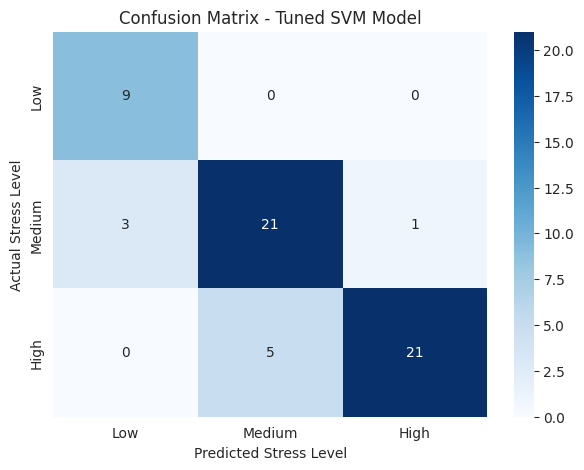

In [ ]:

# Generate confusion matrix

svm_cm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=['Low', 'Medium', 'High']
)

# Visualize confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title("Confusion Matrix - Tuned SVM Model")
plt.xlabel("Predicted Stress Level")
plt.ylabel("Actual Stress Level")

plt.show()


In [ ]:

# Generate classification report

svm_report = classification_report(
    y_test,
    y_pred_svm,
    labels=['Low', 'Medium', 'High'],
    target_names=[
        'Low Stress',
        'Medium Stress',
        'High Stress'
    ],
    zero_division=0
)

print("Classification Report - Tuned SVM Model\n")
print(svm_report)


Classification Report - Tuned SVM Model

               precision    recall  f1-score   support

   Low Stress       0.75      1.00      0.86         9
Medium Stress       0.81      0.84      0.82        25
  High Stress       0.95      0.81      0.88        26

     accuracy                           0.85        60
    macro avg       0.84      0.88      0.85        60
 weighted avg       0.86      0.85      0.85        60



In [ ]:

# Final SVM model summary

print("\n1. INITIAL MODEL PERFORMANCE")
print(svm_initial_results.to_string(index=False))
print("\n2. BEST HYPERPARAMETERS")
print(svm_best_params)

print("\n3. BEST CROSS-VALIDATION MACRO F1-SCORE")
print(round(svm_best_cv_f1, 4))


1. INITIAL MODEL PERFORMANCE
         Metric  Initial SVM
       Accuracy     0.766667
Macro Precision     0.783333
   Macro Recall     0.794245
 Macro F1-score     0.781624

2. BEST HYPERPARAMETERS
{'svm__C': 10, 'svm__class_weight': 'balanced', 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}

3. BEST CROSS-VALIDATION MACRO F1-SCORE
0.8731


In [ ]:
# Define svm_final_results using the calculated metrics
svm_final_results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Macro Precision',
        'Macro Recall',
        'Macro F1-score'
    ],
    'Final Tuned SVM': [
        svm_final_accuracy,
        svm_final_precision,
        svm_final_recall,
        svm_final_f1
    ]
})

print("\n4. FINAL TEST PERFORMANCE")
print(svm_final_results.to_string(index=False))


4. FINAL TEST PERFORMANCE
         Metric  Final Tuned SVM
       Accuracy         0.850000
Macro Precision         0.837413
   Macro Recall         0.882564
 Macro F1-score         0.851891


In [ ]:
print("\n5. CONFUSION MATRIX")
print(svm_cm)


5. CONFUSION MATRIX
[[ 9  0  0]
 [ 3 21  1]
 [ 0  5 21]]


In [ ]:
print("\n6. CLASSIFICATION REPORT")
print(svm_report)


6. CLASSIFICATION REPORT
               precision    recall  f1-score   support

   Low Stress       0.75      1.00      0.86         9
Medium Stress       0.81      0.84      0.82        25
  High Stress       0.95      0.81      0.88        26

     accuracy                           0.85        60
    macro avg       0.84      0.88      0.85        60
 weighted avg       0.86      0.85      0.85        60




# Part 2: Common Team Workflow

## Step 1: Collection of Results from All Four Models

After completing the individual implementation and hyperparameter tuning of all four classification models, we will collect their evaluation results in one place.

The four models implemented are:

1. Random Forest
2. Logistic Regression
3. K-Nearest Neighbors (KNN)
4. Support Vector Machine (SVM)

For each model, we will collect:

- Initial model performance.
- Best hyperparameters obtained through GridSearchCV.
- Best cross-validation Macro F1-score.
- Final test Accuracy.
- Final test Precision (Macro).
- Final test Recall (Macro).
- Final test Macro F1-score.

These results will provide a common basis for comparing the performance of all four models in the next stage.


In [ ]:
# Import Pandas
import pandas as pd

# Collect the results of all four models

team_results = pd.DataFrame({

    'Model': [
        'Random Forest',
        'Logistic Regression',
        'KNN',
        'SVM'
    ],

    'Initial Accuracy': [
        0.8500,
        0.7167,
        0.8167,
        0.7667
    ],

    'Initial Macro F1': [
        0.8689,
        0.7432,
        0.8173,
        0.7816
    ],

    'Best Hyperparameters': [
        'max_depth=15, min_samples_leaf=1, n_estimators=100',
        'C=0.01, penalty=l2',
        'n_neighbors=3, p=1, weights=distance',
        'C=10, kernel=rbf, gamma=scale, class_weight=balanced'
    ],

    'Best CV Macro F1': [
        0.8775,
        0.7102,
        0.9049,
        0.8731
    ],

    'Test Accuracy': [
        0.8667,
        0.7667,
        0.8833,
        0.8500
    ],

    'Test Precision (Macro)': [
        0.9192,
        0.8271,
        0.9000,
        0.8374
    ],

    'Test Recall (Macro)': [
        0.8732,
        0.7695,
        0.9097,
        0.8826
    ],

    'Test Macro F1': [
        0.8826,
        0.7919,
        0.8966,
        0.8519
    ]

})

# Display consolidated results

display(team_results.round(4))

,Model,Initial Accuracy,Initial Macro F1,Best Hyperparameters,Best CV Macro F1,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test Macro F1
0,Random Forest,0.8500,0.8689,"max_depth=15, min_samples_leaf=1, n_estimators...",0.8775,0.8667,0.9192,0.8732,0.8826
1,Logistic Regression,0.7167,0.7432,"C=0.01, penalty=l2",0.7102,0.7667,0.8271,0.7695,0.7919
2,KNN,0.8167,0.8173,"n_neighbors=3, p=1, weights=distance",0.9049,0.8833,0.9000,0.9097,0.8966
3,SVM,0.7667,0.7816,"C=10, kernel=rbf, gamma=scale, class_weight=ba...",0.8731,0.8500,0.8374,0.8826,0.8519


In [ ]:
# Identify the model with the highest CV Macro F1-score

best_cv_model = team_results.loc[
    team_results['Best CV Macro F1'].idxmax()
]

print("Model with Highest Cross-Validation Macro F1:")
print("Model:", best_cv_model['Model'])
print("CV Macro F1:", best_cv_model['Best CV Macro F1'])

Model with Highest Cross-Validation Macro F1:
Model: KNN
CV Macro F1: 0.9049



## Step 2: Comparative Performance Analysis of All Four Models

After collecting the individual results of Random Forest, Logistic Regression, K-Nearest Neighbors (KNN) and Support Vector Machine (SVM), we will compare their performance using a common set of evaluation metrics.

The comparison will include:

1. Initial Accuracy
2. Initial Macro F1-score
3. Best Cross-Validation Macro F1-score
4. Final Test Accuracy
5. Final Test Precision (Macro)
6. Final Test Recall (Macro)
7. Final Test Macro F1-score

Using identical evaluation metrics ensures a fair comparison between all four classification models.

This comparison will help us understand the strengths and weaknesses of each model and support the selection of the final model.


Create the comparative performance table

In [ ]:
# Create a comparative performance table

comparison_table = team_results[[
    'Model',
    'Initial Accuracy',
    'Initial Macro F1',
    'Best CV Macro F1',
    'Test Accuracy',
    'Test Precision (Macro)',
    'Test Recall (Macro)',
    'Test Macro F1'
]].copy()

# Sort models according to Cross-Validation Macro F1
comparison_table = comparison_table.sort_values(
    by='Best CV Macro F1',
    ascending=False
).reset_index(drop=True)

# Display comparison table
display(comparison_table.round(4))

,Model,Initial Accuracy,Initial Macro F1,Best CV Macro F1,Test Accuracy,Test Precision (Macro),Test Recall (Macro),Test Macro F1
0,KNN,0.8167,0.8173,0.9049,0.8833,0.9000,0.9097,0.8966
1,Random Forest,0.8500,0.8689,0.8775,0.8667,0.9192,0.8732,0.8826
2,SVM,0.7667,0.7816,0.8731,0.8500,0.8374,0.8826,0.8519
3,Logistic Regression,0.7167,0.7432,0.7102,0.7667,0.8271,0.7695,0.7919



## Step 3: Comparison of Confusion Matrices

A confusion matrix is an evaluation technique used to assess the classification performance of a machine learning model.

It compares the actual class labels with the predicted class labels and helps identify both correct predictions and misclassifications.

In our project, the target variable consists of three stress categories:

- Low Stress
- Medium Stress
- High Stress

We will compare the confusion matrices of all four classification models:

1. Random Forest
2. Logistic Regression
3. K-Nearest Neighbors (KNN)
4. Support Vector Machine (SVM)

This comparison will help us understand how effectively each model classifies students into different stress categories and identify which categories are more difficult to predict.

All four models will be evaluated using the same test dataset to ensure a fair comparison.



### 3.2 Preparation of Trained Classification Models

Before generating the confusion matrices, we will collect the best-performing versions of all four classification models.

The tuned models will be used wherever available so that the comparison reflects their performance after hyperparameter optimization.

The Logistic Regression pipeline will be fitted using its previously identified best hyperparameters.


In [ ]:
# Prepare all four classification models

# Fit Logistic Regression using its best hyperparameters
logistic_pipeline.set_params(
    logistic__C=0.01,
    logistic__penalty='l2'
)

logistic_pipeline.fit(X_train, y_train)


# Collect all four trained models
final_models = {
    'Random Forest': best_rf_model,
    'Logistic Regression': logistic_pipeline,
    'K-Nearest Neighbors (KNN)': grid_search.best_estimator_,
    'Support Vector Machine (SVM)': svm_grid_search.best_estimator_
}

print("All four classification models are ready.")

for model_name in final_models:
    print("-", model_name)

All four classification models are ready.
- Random Forest
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)



### 3.3 Generation of Confusion Matrices for All Four Models

We will now generate confusion matrices for all four classification models using the same test dataset.

For consistency, the stress categories will be arranged in the same order: Low, Medium and High.

The four confusion matrices will be displayed together in a 2 × 2 subplot layout, making it easier to visually compare the classification performance of each model.


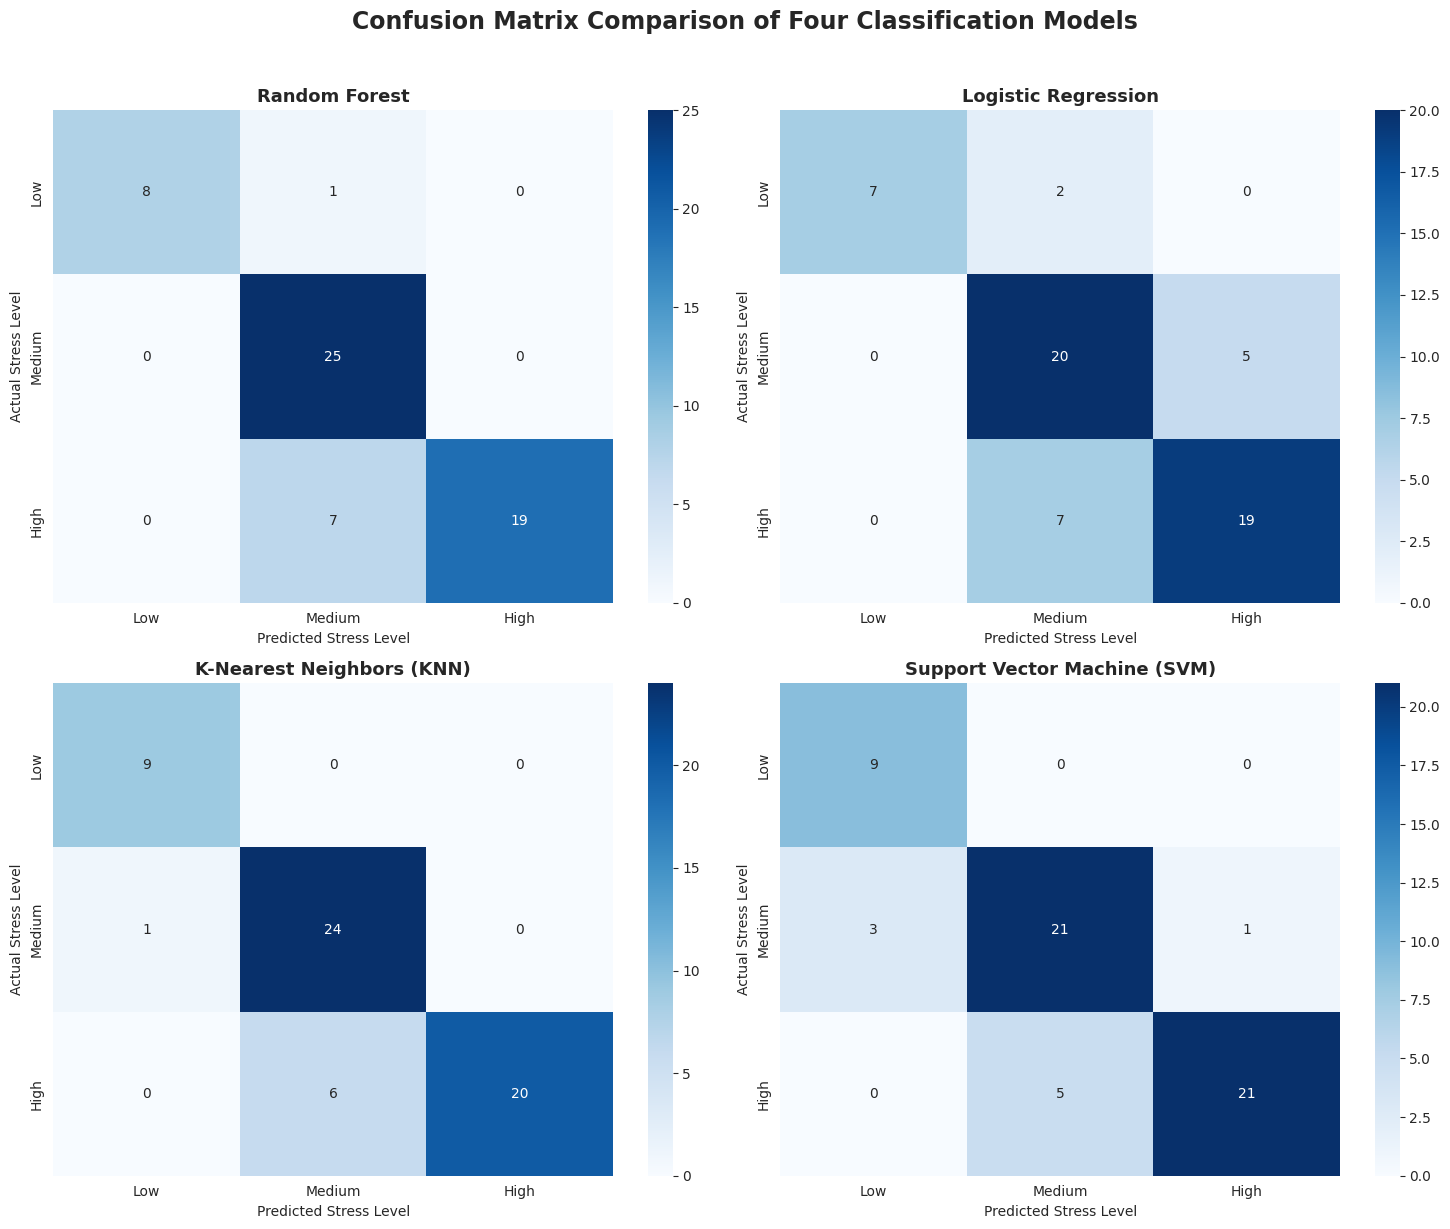

In [ ]:
# Import required libraries

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix


# Define the order of stress categories
class_labels = ['Low', 'Medium', 'High']


# Create a 2 × 2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

axes = axes.flatten()


# Generate confusion matrices for all four models
for i, (model_name, model) in enumerate(final_models.items()):

    # Generate predictions on the test dataset
    y_pred = model.predict(X_test)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    # Plot confusion matrix
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_labels,
        yticklabels=class_labels,
        ax=axes[i]
    )

    # Add title and axis labels
    axes[i].set_title(
        model_name,
        fontsize=13,
        fontweight='bold'
    )

    axes[i].set_xlabel('Predicted Stress Level')
    axes[i].set_ylabel('Actual Stress Level')


# Add overall title
plt.suptitle(
    'Confusion Matrix Comparison of Four Classification Models',
    fontsize=17,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.show()


### 3.4 Interpretation of Confusion Matrices

The confusion matrices provide a detailed comparison of the classification performance of all four models.

The K-Nearest Neighbors (KNN) model achieved the highest number of correct predictions, correctly classifying 53 out of 60 observations. It performed particularly well in identifying Low and Medium stress categories.

Random Forest correctly classified 52 observations, demonstrating strong performance, particularly for the Medium stress category.

The Support Vector Machine (SVM) correctly classified 51 observations, while Logistic Regression correctly classified 46 observations.

An important observation is that High stress cases were comparatively more difficult to classify correctly for some models, with several observations being misclassified as Medium stress.

Overall, KNN demonstrated the strongest test-set classification performance among the four models, followed by Random Forest, SVM and Logistic Regression.



## Step 4: Selection of the Best Performing Model

After comparing the performance of all four classification models, the next step is to select the most suitable model for our project.

Model selection is based primarily on the cross-validated Macro F1-score, while test performance is also considered to evaluate how well the models generalize to unseen data.

Macro F1-score is particularly useful for our project because it calculates the F1-score independently for each stress category (Low, Medium and High) and then takes their average.

The model with the highest cross-validated Macro F1-score will be given priority, while its test performance will be examined as additional evidence of its classification ability.

Based on this comparison, we will select the most suitable model for further analysis.



### 4.2 Comparison of Cross-Validation and Test Performance

We will compare the cross-validated Macro F1-scores and test Macro F1-scores of all four classification models.

Cross-validation provides an estimate of how consistently a model performs across different training and validation splits, whereas test performance evaluates its predictive ability on the held-out test dataset.

Both metrics will be considered to identify the most suitable classification model.


In [ ]:
import pandas as pd

# Create a comparison of CV and test performance

model_selection_results = pd.DataFrame({

    'Model': [
        'KNN',
        'Random Forest',
        'SVM',
        'Logistic Regression'
    ],

    'Best CV Macro F1': [
        0.9049,
        0.8775,
        0.8731,
        0.7102
    ],

    'Test Accuracy': [
        0.8833,
        0.8667,
        0.8500,
        0.7667
    ],

    'Test Macro F1': [
        0.8966,
        0.8826,
        0.8519,
        0.7919
    ]
})

# Sort according to cross-validated Macro F1
model_selection_results = model_selection_results.sort_values(
    by='Best CV Macro F1',
    ascending=False
).reset_index(drop=True)

print("Model Selection Comparison:")

display(model_selection_results)

Model Selection Comparison:


,Model,Best CV Macro F1,Test Accuracy,Test Macro F1
0,KNN,0.9049,0.8833,0.8966
1,Random Forest,0.8775,0.8667,0.8826
2,SVM,0.8731,0.8500,0.8519
3,Logistic Regression,0.7102,0.7667,0.7919



### 4.3 Selection of the Best Performing Model

Based on the comparison of cross-validated and test Macro F1-scores, the K-Nearest Neighbors (KNN) model demonstrates the strongest overall performance.

It achieved the highest cross-validated Macro F1-score of 0.9049 and the highest test Macro F1-score of 0.8966 among the four classification models.

The model also achieved a test accuracy of 88.33%, indicating strong predictive performance on unseen observations.

Therefore, KNN is selected as the best-performing model for further analysis in our project.

The selection is supported by both its cross-validation results and its performance on the independent test dataset.


In [ ]:
# Select the best-performing model

best_model_name = 'KNN'

best_model = final_models['K-Nearest Neighbors (KNN)']

print("Selected Model:", best_model_name)

print("Best CV Macro F1:",
      round(grid_search.best_score_, 4))

print("Test Accuracy: 0.8833")

print("Test Macro F1: 0.8966")

Selected Model: KNN
Best CV Macro F1: 0.9049
Test Accuracy: 0.8833
Test Macro F1: 0.8966



### 4.4 Final Model Selection Summary

The K-Nearest Neighbors (KNN) classifier has been selected as the final model based on its superior cross-validated Macro F1-score and strong test performance.

Its ability to achieve consistent classification performance across the three stress categories makes it a suitable choice for our student stress-level classification problem.

The selected KNN model will be used for the subsequent feature importance analysis and final pipeline preparation.



## Step 5: Feature Importance Using Permutation Importance

Feature importance helps us understand which input features contribute most to the predictions made by a machine learning model.

In our project, we will use Permutation Feature Importance to identify the academic and lifestyle factors that are most influential in predicting students' stress levels.

Permutation Feature Importance works by randomly shuffling the values of one feature at a time while keeping the remaining features unchanged.

The model's performance is then evaluated again to observe how much its predictive performance decreases.

If shuffling a feature causes a significant decrease in the Macro F1-score, that feature is considered important for the model's predictions.

We will apply this technique to our selected K-Nearest Neighbors (KNN) model using the test dataset.



### 5.2 Calculation of Permutation Feature Importance

We will calculate permutation feature importance using the selected KNN model.

The Macro F1-score will be used as the evaluation metric because our classification problem involves three stress categories: Low, Medium and High.

Each feature will be shuffled multiple times to obtain a more reliable estimate of its importance.

A higher positive importance score indicates that the model's predictive performance decreases more when that feature is shuffled, suggesting that the feature contributes more to the model's predictions.


In [ ]:
# Import permutation importance

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np

# Calculate permutation feature importance
permutation_results = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

print("Permutation Feature Importance calculated successfully!")

Permutation Feature Importance calculated successfully!



### 5.3 Feature Importance Results

After calculating permutation importance, we will organize the importance scores of all input features into a table.

The mean importance score represents the average decrease in the Macro F1-score after randomly shuffling a particular feature.

The standard deviation indicates the variation in importance scores across repeated permutations.

The features will be arranged in descending order of their mean importance scores to identify the most influential features in predicting students' stress levels.


In [ ]:
# Identify feature names

if hasattr(X_test, 'columns'):
    feature_names = X_test.columns.tolist()

elif hasattr(best_model, 'feature_names_in_'):
    feature_names = best_model.feature_names_in_.tolist()

elif 'new_feature_names' in globals() and len(new_feature_names) == len(permutation_results.importances_mean):
    feature_names = new_feature_names

else:
    feature_names = [
        f'Feature {i+1}'
        for i in range(len(permutation_results.importances_mean))
    ]


# Create feature importance DataFrame

feature_importance_df = pd.DataFrame({

    'Feature': feature_names,

    'Mean Importance': permutation_results.importances_mean,

    'Standard Deviation': permutation_results.importances_std

})


# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Mean Importance',
    ascending=False
).reset_index(drop=True)


# Display results

print("Permutation Feature Importance Results:")

display(feature_importance_df.round(4))

Permutation Feature Importance Results:


,Feature,Mean Importance,Standard Deviation
0,Examination_Pressure,0.0588,0.0302
1,Unexpected_Difficulties,0.0558,0.0231
2,Competing_Responsibilities,0.0544,0.0250
3,Sleep_Difficulties,0.0406,0.0214
4,Lack_of_Social_Support,0.0372,0.0252
5,Time_Management,0.0355,0.0244
6,Lack_of_Control,0.0292,0.0170
7,Academic_Workload,0.0234,0.0205
8,Career_Pressure,0.0172,0.0201
9,Deadline_Pressure,0.0078,0.0258



### 5.4 Visualization of Permutation Feature Importance

To make the results easier to interpret, we will visualize the permutation feature importance scores using a horizontal bar chart.

The features will be displayed in descending order of importance.

Features with larger positive importance scores indicate a greater contribution to the predictive performance of the selected KNN model.

The visualization will help us identify the academic and lifestyle factors that are most influential in predicting students' stress levels.


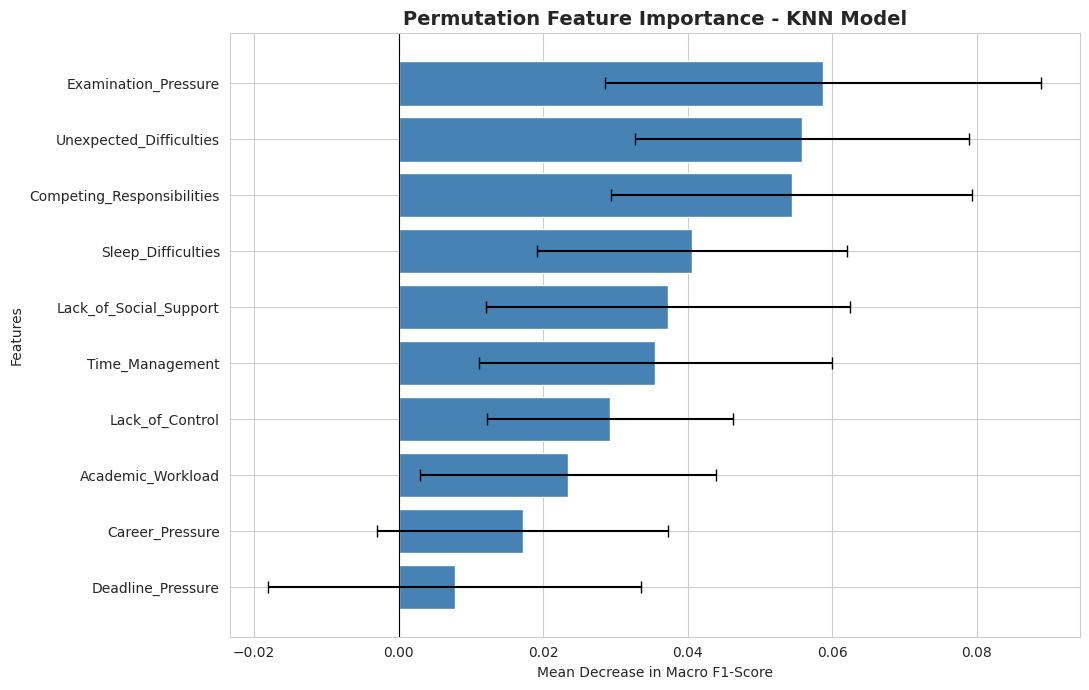

In [ ]:
# Visualize permutation feature importance

import matplotlib.pyplot as plt
import seaborn as sns

# Sort features in ascending order for horizontal plotting
plot_data = feature_importance_df.sort_values(
    by='Mean Importance',
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data['Feature'],
    plot_data['Mean Importance'],
    xerr=plot_data['Standard Deviation'],
    capsize=4,
    color='steelblue'
)

plt.axvline(
    x=0,
    color='black',
    linewidth=0.8
)

plt.xlabel('Mean Decrease in Macro F1-Score')
plt.ylabel('Features')

plt.title(
    'Permutation Feature Importance - KNN Model',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


### 5.5 Interpretation of Permutation Feature Importance

The permutation feature importance analysis identifies the relative contribution of different academic and lifestyle factors to the predictive performance of the selected KNN model.

The results indicate that Examination Pressure has the highest mean importance score (0.0588), followed by Unexpected Difficulties (0.0558) and Competing Responsibilities (0.0544). This suggests that these factors have a relatively greater influence on the model's predictions of student stress levels.

Sleep Difficulties (0.0406), Lack of Social Support (0.0372) and Time Management (0.0355) also demonstrate meaningful contributions to the model's predictive performance.

On the other hand, Career Pressure (0.0172) and Deadline Pressure (0.0078) have comparatively lower mean importance scores.

Overall, the findings suggest that examination-related pressure, unexpected difficulties and competing responsibilities are among the most influential features used by the selected KNN model to distinguish between Low, Medium and High stress categories.

These results represent model-specific predictive importance and should not be interpreted as evidence of causal relationships between the identified factors and student stress.



## Step 6: Saving the Final Pipeline

After selecting K-Nearest Neighbors (KNN) as the best-performing classification model, the final step is to save the trained model pipeline.

Saving the pipeline allows us to reuse the trained model without repeating the entire training and preprocessing process.

We will use the Joblib library to save the complete fitted KNN pipeline.

The saved pipeline will preserve the preprocessing and classification steps included within it, along with the learned parameters of the trained model.

The final pipeline will be stored in Google Drive so that it can be accessed and reused in future applications or analysis.



### 6.2 Checking the Selected Model Pipeline

Before saving the final model, we will verify that the selected KNN model is a fitted Scikit-learn Pipeline.

We will also examine its individual steps to confirm which preprocessing operations and classification components are included.

This ensures that we save the complete fitted pipeline rather than saving only the classification algorithm.


In [ ]:
# Import required library

from sklearn.pipeline import Pipeline
from sklearn.utils.validation import check_is_fitted

# Check whether the selected model is a Pipeline

print("Selected Model:", best_model_name)

print("\nPipeline Type:")
print(type(best_model))

# Verify that the model is a Pipeline
if not isinstance(best_model, Pipeline):
    raise TypeError(
        "The selected model is not a Scikit-learn Pipeline. "
        "Please check the model selection cell before saving."
    )

# Check whether the pipeline is fitted
check_is_fitted(best_model)

print("\nPipeline is fitted successfully!")

# Display pipeline steps
print("\nSteps Included in the Final Pipeline:")

for step_name, step_object in best_model.named_steps.items():
    print(f"{step_name}: {step_object}")

Selected Model: KNN

Pipeline Type:
<class 'sklearn.pipeline.Pipeline'>

Pipeline is fitted successfully!

Steps Included in the Final Pipeline:
imputer: SimpleImputer(strategy='median')
scaler: StandardScaler()
knn: KNeighborsClassifier(n_neighbors=3, p=1, weights='distance')



### 6.3 Saving the Final KNN Pipeline

We will now save the fitted KNN pipeline using the Joblib library.

The pipeline will be saved in a dedicated folder in Google Drive so that it can be accessed later.

Saving the fitted pipeline preserves its learned parameters and the preprocessing steps included within it.

This allows us to reuse the selected model without training it again.


In [ ]:
# Import required libraries

import joblib
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Create a folder for saving the final model
save_folder = '/content/drive/MyDrive/ML_Project_Artifacts'

os.makedirs(save_folder, exist_ok=True)

# Define the file path
model_path = os.path.join(
    save_folder,
    'Best_KNN_Pipeline.joblib'
)

# Save the complete fitted pipeline
joblib.dump(best_model, model_path)

print("Final KNN Pipeline saved successfully!")

print("\nSaved Location:")
print(model_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Final KNN Pipeline saved successfully!

Saved Location:
/content/drive/MyDrive/ML_Project_Artifacts/Best_KNN_Pipeline.joblib



### 6.4 Verification of the Saved Pipeline

After saving the final pipeline, we will load it again using Joblib to verify that it has been stored correctly.

We will compare the predictions made by the original fitted pipeline and the loaded pipeline on the same test dataset.

If both pipelines generate identical predictions, it confirms that the saved pipeline can be successfully reused.


In [ ]:
# Load the saved KNN pipeline

loaded_model = joblib.load(model_path)

# Generate predictions using both pipelines

original_predictions = best_model.predict(X_test)

loaded_predictions = loaded_model.predict(X_test)

# Compare predictions

if np.array_equal(original_predictions, loaded_predictions):

    print("Pipeline verification successful!")

    print("Original and loaded model predictions are identical.")

else:

    print("Pipeline verification failed.")

# Display loaded model information

print("\nLoaded Model:")
print(loaded_model)

Pipeline verification successful!
Original and loaded model predictions are identical.

Loaded Model:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('knn',
                 KNeighborsClassifier(n_neighbors=3, p=1, weights='distance'))])



### 6.5 Final Pipeline Saving Summary

The selected K-Nearest Neighbors (KNN) model pipeline was successfully saved using the Joblib library.

The fitted pipeline was stored in Google Drive, allowing it to be reused without repeating the model training process.

The saved pipeline was subsequently loaded and tested on the same test dataset. The predictions generated by the original and loaded pipelines were identical, confirming successful storage and retrieval.

Thus, the final selected KNN pipeline is preserved and ready for future use.
